# Vivir más sin ser más rico

**Trabajo Práctico Final · Visualización de la Información · ITBA · Noviembre de 2026**
Javier Peral Belmont y Pilar Frutos

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/za0sec/infovis/blob/main/TPFinal/vivir_mas_sin_ser_mas_rico.ipynb)

¿Cuánto se parecen la riqueza de un país y los años que vive su gente? En este notebook exploramos datos del Banco Mundial obtenidos con la API de **Data360** y contamos la historia en tres gráficos interactivos:

1. **PIB por habitante y esperanza de vida (2024).** Los países más ricos suelen vivir más, pero algunos viven bastante más (o menos) de lo que les correspondería por su ingreso.
2. **Acceso básico al agua para beber y esperanza de vida (2000–2024).** Un servicio esencial, cómo se relaciona con la longevidad y cómo cambió esa relación.
3. **Vacunación infantil contra el sarampión y esperanza de vida (2000–2024).** Una medida de prevención que plantea una pregunta distinta a la del agua.

**Cómo ejecutarlo.** En Colab: *Entorno de ejecución → Ejecutar todo*. Las primeras celdas instalan dos dependencias y descargan los datos directamente de la API (alrededor de un minuto). No hace falta subir archivos ni usar Drive. Los gráficos se dibujan con D3 dentro de las salidas de las celdas y necesitan conexión a internet para cargar la biblioteca.

**Contenido**
- 0. Preparación
- 1. Exploración de datos
- 2. Gráfico 1 — PIB por habitante y esperanza de vida
- 3. Gráfico 2 — Agua para beber y esperanza de vida
- 4. Gráfico 3 — Vacunación contra el sarampión y esperanza de vida
- 5. Conclusiones
- 6. Fuentes, método y verificación

## 0. Preparación

`babel` y `pycountry` sirven para poner los nombres de los países en castellano. El resto de las bibliotecas ya viene instalado en Colab.

In [ ]:
%pip install -q babel pycountry

In [2]:
import html
import json
import time
import uuid
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycountry
import requests
from babel import Locale
from IPython.display import HTML, display

BASE = "https://data360api.worldbank.org/data360"
REPO = "https://raw.githubusercontent.com/za0sec/infovis/main/TPFinal/"   # versión publicada del artículo
DESDE, HASTA = 2000, 2024
pd.set_option("display.width", 140)


In [3]:
def pedir(metodo, ruta, intentos=6, **kwargs):
    """Llama a la API reintentando: a veces responde con el cuerpo vacío o corta la conexión."""
    for intento in range(intentos):
        try:
            r = requests.request(metodo, f"{BASE}/{ruta}", timeout=120, **kwargs)
            r.raise_for_status()
            return r.json()
        except (requests.RequestException, ValueError):
            if intento == intentos - 1:
                raise
            time.sleep(2 * (intento + 1))


def traer_datos(indicador, base="WB_WDI"):
    """Descarga todas las observaciones de un indicador (la API pagina de a 1000 filas)."""
    filas, skip = [], 0
    while True:
        pagina = pedir("GET", "data", params={"DATABASE_ID": base, "INDICATOR": indicador, "top": 1000, "skip": skip})
        filas += pagina["value"]
        skip += 1000
        if skip >= pagina["count"]:
            return pd.DataFrame(filas)


def a_serie(crudo, nombre):
    """Pasa las observaciones SDMX a una tabla país–año con una sola columna de valores."""
    d = crudo
    for dim in ["SEX", "AGE", "URBANISATION"]:
        if dim in d and d[dim].nunique() > 1:
            d = d[d[dim] == "_T"]
    return pd.DataFrame({
        "iso3": d["REF_AREA"],
        "anio": d["TIME_PERIOD"].astype(int),
        nombre: pd.to_numeric(d["OBS_VALUE"], errors="coerce"),
    }).dropna()


## 1. Exploración de datos

### 1.1 Los indicadores

Data360 reúne más de 170 bases de datos del Banco Mundial y otros organismos. Trabajamos con **World Development Indicators** (`WB_WDI`), que tiene series anuales por país para casi todo el período. Cada indicador se identifica con el código de WDI precedido por la base: `SP.DYN.LE00.IN` pasa a ser `WB_WDI_SP_DYN_LE00_IN`.

Además de los indicadores del primer gráfico, evaluamos los tres que propone la consigna y tres alternativas para el tercer gráfico. Antes de usarlos consultamos su ficha en el endpoint `/metadata` para respetar el nombre y la unidad originales.

In [4]:
INDICADORES = {
    # clave: (código Data360, nombre en castellano, unidad)
    "vida": ("WB_WDI_SP_DYN_LE00_IN", "Esperanza de vida al nacer", "años"),
    "pib": ("WB_WDI_NY_GDP_PCAP_PP_KD", "PIB per cápita en paridad de poder adquisitivo", "$ internacionales constantes de 2021"),
    "poblacion": ("WB_WDI_SP_POP_TOTL", "Población total", "personas"),
    "agua": ("WB_WDI_SH_H2O_BASW_ZS", "Población que usa al menos un servicio básico de agua para beber", "% de la población"),
    "secundaria": ("WB_WDI_SE_SEC_CMPT_LO_ZS", "Tasa de finalización del primer ciclo de secundaria", "% del grupo de edad correspondiente"),
    "sarampion": ("WB_WDI_SH_IMM_MEAS", "Inmunización contra el sarampión (primera dosis)", "% de niños de 12 a 23 meses"),
    "dpt": ("WB_WDI_SH_IMM_IDPT", "Inmunización contra difteria, tos convulsa y tétanos (DPT)", "% de niños de 12 a 23 meses"),
    "saneamiento": ("WB_WDI_SH_STA_BASS_ZS", "Población que usa al menos servicios básicos de saneamiento", "% de la población"),
    "uhc": ("WB_WDI_SH_UHC_SCI", "Índice de cobertura de servicios de salud (UHC)", "índice de 0 a 100"),
}

fichas = []
for clave, (codigo, nombre, unidad) in INDICADORES.items():
    meta = pedir("POST", "metadata", json={"query": f"&$filter=series_description/idno eq '{codigo}'"})
    sd = meta["value"][0]["series_description"]
    fichas.append({"clave": clave, "código": codigo, "nombre original": sd["name"],
                   "unidad original": sd.get("measurement_unit"), "nombre en el notebook": nombre, "unidad": unidad})
pd.DataFrame(fichas).set_index("clave")


,código,nombre original,unidad original,nombre en el notebook,unidad
clave,,,,,
vida,WB_WDI_SP_DYN_LE00_IN,"Life expectancy at birth, total (years)",Years,Esperanza de vida al nacer,años
pib,WB_WDI_NY_GDP_PCAP_PP_KD,"GDP per capita, PPP (constant 2021 internation...",Constant 2021 international $,PIB per cápita en paridad de poder adquisitivo,$ internacionales constantes de 2021
poblacion,WB_WDI_SP_POP_TOTL,"Population, total",Unit,Población total,personas
agua,WB_WDI_SH_H2O_BASW_ZS,People using at least basic drinking water ser...,% of population,Población que usa al menos un servicio básico ...,% de la población
secundaria,WB_WDI_SE_SEC_CMPT_LO_ZS,"Lower secondary completion rate, total (% of r...",% of relevant age group,Tasa de finalización del primer ciclo de secun...,% del grupo de edad correspondiente
sarampion,WB_WDI_SH_IMM_MEAS,"Immunization, measles (% of children ages 12-2...",Percentage,Inmunización contra el sarampión (primera dosis),% de niños de 12 a 23 meses
dpt,WB_WDI_SH_IMM_IDPT,"Immunization, DPT (% of children ages 12-23 mo...",Percentage,"Inmunización contra difteria, tos convulsa y t...",% de niños de 12 a 23 meses
saneamiento,WB_WDI_SH_STA_BASS_ZS,People using at least basic sanitation service...,% of population,Población que usa al menos servicios básicos d...,% de la población
uhc,WB_WDI_SH_UHC_SCI,UHC service coverage index,Index,Índice de cobertura de servicios de salud (UHC),índice de 0 a 100


Dos detalles de las fichas que condicionan la lectura:

- El indicador de agua mide **porcentaje de la población** que usa al menos un servicio básico: una fuente mejorada a no más de 30 minutos, ida y vuelta. No mide calidad del agua (eso es «gestionado de forma segura», otra serie).
- La finalización de secundaria es una tasa **bruta**: cuenta a todos los que llegan al último grado, tengan la edad que tengan, así que puede superar el 100 %.

Descargamos todas las observaciones de cada indicador:

In [5]:
crudos = {}
for clave, (codigo, _, _) in INDICADORES.items():
    crudos[clave] = traer_datos(codigo)
    d = crudos[clave]
    print(f"{clave:12} {len(d):6} filas  {d['TIME_PERIOD'].min()}–{d['TIME_PERIOD'].max()}  {d['REF_AREA'].nunique()} códigos de país o agregado")


vida          17191 filas  1960–2024  265 códigos de país o agregado


pib            8705 filas  1990–2025  247 códigos de país o agregado


poblacion     17460 filas  1960–2025  265 códigos de país o agregado


agua           6398 filas  2000–2024  262 códigos de país o agregado


secundaria     5939 filas  1970–2025  242 códigos de país o agregado


sarampion     10046 filas  1980–2024  241 códigos de país o agregado


dpt           10169 filas  1980–2024  241 códigos de país o agregado


saneamiento    6363 filas  2000–2024  262 códigos de país o agregado


uhc            5784 filas  2000–2023  241 códigos de país o agregado


Cada fila es una observación con formato SDMX: el área (`REF_AREA`), el año (`TIME_PERIOD`), el valor (`OBS_VALUE`, que llega como texto) y las dimensiones de desagregación (sexo, edad, urbanización). En estos indicadores todas valen `_T` (total).

In [6]:
v = crudos["vida"]
v[(v["REF_AREA"] == "ARG") & (v["TIME_PERIOD"].astype(int) == 2024)].T

,8565
OBS_VALUE,77.543
TIME_FORMAT,P1Y
UNIT_MULT,0
COMMENT_OBS,None
OBS_STATUS,A
OBS_CONF,PU
AGG_METHOD,_Z
DECIMALS,2
COMMENT_TS,None
DATA_SOURCE,None


### 1.2 Países, no agregados

La API mezcla países con agregados como `WLD` (mundo), `LCN` (América Latina y el Caribe) o `HIC` (ingreso alto). Para que un agregado no cuente como un punto más, nos quedamos solo con las economías que aparecen en la jerarquía de regiones del Banco Mundial (`/portal/v1/hierarchy`). De ahí sale también la región y el grupo de ingreso de cada país.

In [7]:
jer = pedir("GET", "portal/v1/hierarchy", params={"type": "country"})["data"]

REGIONES = {
    "East Asia & Pacific": "Asia oriental y Pacífico",
    "Europe & Central Asia": "Europa y Asia central",
    "Latin America & Caribbean": "América Latina y el Caribe",
    "Middle East, North Africa, Afghanistan & Pakistan": "Medio Oriente, norte de África, Afganistán y Pakistán",
    "North America": "América del Norte",
    "South Asia": "Asia meridional",
    "Eastern and Southern Africa": "África subsahariana",
    "Western and Central Africa": "África subsahariana",
}
INGRESOS = {"Low income": "Bajo", "Lower middle income": "Medio bajo", "Upper middle income": "Medio alto", "High income": "Alto"}

regiones = pd.DataFrame([{"iso3": c["id"], "nombre_en": c["name"], "region": REGIONES[g["name"]]}
                         for g in jer["HCL_WB_REGIONS"] for c in g["countries"]])
ingresos = pd.DataFrame([{"iso3": c["id"], "ingreso": INGRESOS.get(g["name"])}
                         for g in jer["HCL_WB_INCOME"] for c in g["countries"]])
paises = regiones.merge(ingresos, on="iso3", how="left")

nombres_es = Locale("es").territories
def nombre_es(fila):
    pais = pycountry.countries.get(alpha_3=fila.iso3)
    iso2 = pais.alpha_2 if pais else {"XKX": "XK"}.get(fila.iso3)
    return nombres_es.get(iso2, {"CHI": "Islas del Canal"}.get(fila.iso3, fila.nombre_en))

paises["pais"] = paises.apply(nombre_es, axis=1)

codigos = set(crudos["vida"]["REF_AREA"])
agregados = sorted(codigos - set(paises["iso3"]))
print(f"{len(paises)} economías en la jerarquía · {len(codigos)} códigos con esperanza de vida · {len(agregados)} agregados excluidos")
print("Algunos agregados:", ", ".join(agregados[:24]), "…")


220 economías en la jerarquía · 265 códigos con esperanza de vida · 48 agregados excluidos
Algunos agregados: AFE, AFW, ARB, CEB, CSS, EAP, EAR, EAS, ECA, ECS, EMU, EUU, FCV, HIC, HPC, IBD, IBT, IDA, IDB, IDX, LAC, LCN, LDC, LIC …


Las dos regiones africanas del Banco Mundial se unifican en «África subsahariana», como en el artículo. Con eso armamos un panel país–año desde 1990 con todos los indicadores.

In [8]:
panel = None
for clave in INDICADORES:
    s = a_serie(crudos[clave], clave)
    panel = s if panel is None else panel.merge(s, on=["iso3", "anio"], how="outer")

panel = (panel[panel["anio"].between(1990, HASTA)]
         .merge(paises[["iso3", "pais", "region", "ingreso"]], on="iso3", how="inner")
         .sort_values(["iso3", "anio"], ignore_index=True))
print(panel.shape)
panel.sample(5, random_state=2)


(7595, 14)


,iso3,anio,vida,pib,poblacion,agua,secundaria,sarampion,dpt,saneamiento,uhc,pais,region,ingreso
1709,CYP,2019,81.454000,45454.175781,1286671,99.753710,98.962860,86.0,96.0,99.502639,76.0,Chipre,Europa y Asia central,Alto
6773,TLS,2008,62.858000,3530.882175,1032429,59.681726,56.217232,73.0,79.0,33.556386,36.0,Timor-Leste,Asia oriental y Pacífico,Medio bajo
4817,MWI,2012,59.870000,1518.148038,15709577,63.625041,19.313887,90.0,96.0,27.422602,45.0,Malaui,África subsahariana,Bajo
7307,VIR,2017,79.368293,43277.154652,107281,99.245617,NaN,NaN,NaN,99.209037,NaN,Islas Vírgenes de EE. UU.,América Latina y el Caribe,Alto
6925,TUR,2020,76.525000,28976.717916,83384680,95.952576,131.028015,95.0,98.0,99.230742,77.0,Turquía,Europa y Asia central,Medio alto


### 1.3 ¿Cuántos países tienen los dos datos en cada año?

Para cada candidato contamos, año por año, cuántos países tienen a la vez ese indicador y la esperanza de vida. Medimos además si la muestra cambia de composición con dos indicadores:

- **% de la población:** qué parte de la población de todas las economías del panel representan los países con ambos datos.
- **Coincidencia con 2015:** índice de Jaccard entre el conjunto de países del año y el de 2015 (países en ambos ÷ países en alguno). Vale 1 si son exactamente los mismos y baja a medida que la muestra cambia.

In [9]:
CANDIDATOS = ["agua", "secundaria", "sarampion", "dpt", "saneamiento", "uhc"]
poblacion_total = panel.groupby("anio")["poblacion"].sum()

def cobertura(col, referencia=2015):
    con = panel[panel[col].notna() & panel["vida"].notna()]
    conjuntos = con.groupby("anio")["iso3"].agg(set)
    base = conjuntos.get(referencia, set())
    return pd.DataFrame({
        "países": con.groupby("anio").size(),
        "% población": (con.groupby("anio")["poblacion"].sum() / poblacion_total * 100).round(1),
        "coincidencia con 2015": conjuntos.map(lambda s: len(s & base) / len(s | base)).round(2),
    })

coberturas = {c: cobertura(c) for c in CANDIDATOS}
tabla = pd.concat(coberturas, axis=1).reindex(range(1990, HASTA + 1))
tabla.loc[[1990, 1995, 2000, 2005, 2010, 2015, 2019, 2020, 2022, 2023, 2024]]


agua                                   secundaria                                   sarampion                                    \
     países % población coincidencia con 2015     países % población coincidencia con 2015    países % población coincidencia con 2015   
anio                                                                                                                                     
1990    NaN         NaN                   NaN         43        31.1                  0.22       160        93.3                  0.83   
1995    NaN         NaN                   NaN         36        29.7                  0.21       186        99.5                  0.96   
2000  203.0        93.7                  0.95         76        20.4                  0.32       190        99.6                  0.98   
2005  209.0        99.7                  0.98        113        34.3                  0.53       191        99.7                  0.99   
2010  212.0        99.7                  1.00        128        54.2                  0.63       192        99.6                  0.99   
2015  213.0        99.9                  1.00        126        51.8                  1.00       193        99.8                  1.00   
2019  206.0        99.2                  0.96        137        58.3                  0.66       193        99.8                  1.00   
2020  205.0        99.2                  0.95        128        52.7                  0.57       193        99.8                  1.00   
2022  203.0        99.2                  0.94        135        59.8                  0.59       193        99.8                  1.00   
2023  203.0        99.2                  0.94        135        57.7                  0.58       193        99.8                  1.00   
2024  202.0        98.8                  0.94        108        48.3                  0.50       192        99.7                  0.99   

        dpt                                   saneamiento                                      uhc                                    
     países % población coincidencia con 2015      países % población coincidencia con 2015 países % población coincidencia con 2015  
anio                                                                                                                                  
1990    162        93.3                  0.84         NaN         NaN                   NaN    NaN         NaN                   NaN  
1995    187        99.5                  0.97         NaN         NaN                   NaN    NaN         NaN                   NaN  
2000    190        99.6                  0.98       202.0        96.3                  0.95  193.0        99.8                   1.0  
2005    191        99.7                  0.99       208.0        99.4                  0.98  193.0        99.8                   1.0  
2010    192        99.6                  0.99       210.0        99.4                  0.99  193.0        99.8                   1.0  
2015    193        99.8                  1.00       213.0        99.9                  1.00  193.0        99.8                   1.0  
2019    193        99.8                  1.00       203.0        99.2                  0.94  193.0        99.8                   1.0  
2020    193        99.8                  1.00       202.0        99.2                  0.94  193.0        99.8                   1.0  
2022    193        99.8                  1.00       199.0        99.1                  0.93  193.0        99.8                   1.0  
2023    193        99.8                  1.00       196.0        98.6                  0.91  193.0        99.8                   1.0  
2024    192        99.7                  0.99       193.0        98.1                  0.90    NaN         NaN                   NaN

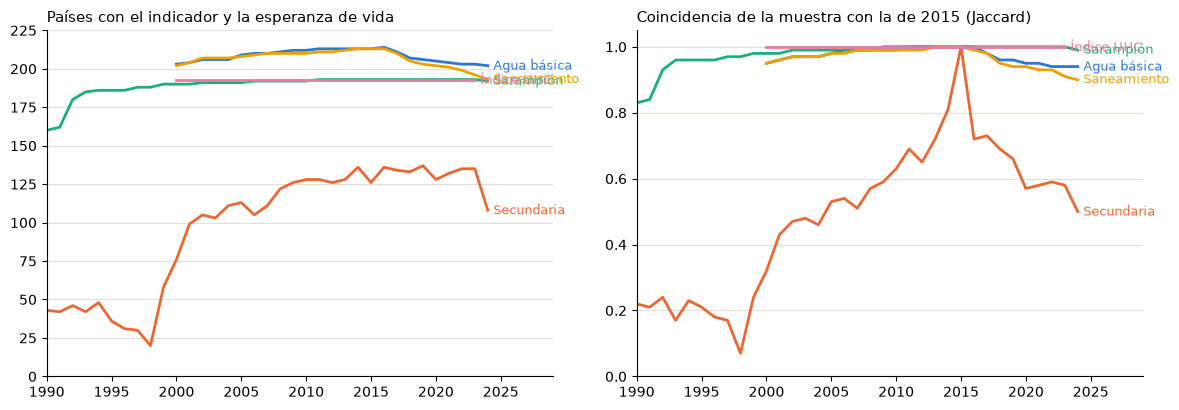

In [10]:
COLORES = {"agua": "#2a78d6", "secundaria": "#eb6834", "sarampion": "#1baf7a", "saneamiento": "#eda100", "uhc": "#e87ba4"}
ETIQUETAS = {"agua": "Agua básica", "secundaria": "Secundaria", "sarampion": "Sarampión", "saneamiento": "Saneamiento", "uhc": "Índice UHC"}

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for clave, color in COLORES.items():
    serie = tabla[clave].dropna(how="all")
    for eje, columna in zip(ejes, ["países", "coincidencia con 2015"]):
        eje.plot(serie.index, serie[columna], color=color, lw=2)
        eje.annotate(ETIQUETAS[clave], (serie.index[-1], serie[columna].iloc[-1]), xytext=(4, 0),
                     textcoords="offset points", va="center", fontsize=9, color=color)
ejes[0].set_title("Países con el indicador y la esperanza de vida", loc="left", fontsize=11)
ejes[1].set_title("Coincidencia de la muestra con la de 2015 (Jaccard)", loc="left", fontsize=11)
ejes[0].set_ylim(0, 225); ejes[1].set_ylim(0, 1.05)
for eje in ejes:
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="y", color="#e1e0d9"); eje.set_axisbelow(True)
    eje.set_xlim(1990, 2029)
plt.tight_layout(); plt.show()


**Lectura.** El agua, el sarampión (y la DPT, que casi coincide con él) y el saneamiento tienen más de 190 países por año y prácticamente la misma muestra en todo el período: la coincidencia con 2015 no baja de 0,9 desde 2000. La secundaria es otra historia: nunca supera los 140 países, en varios años cubre a menos de la mitad de la población y la muestra cambia mucho de un año a otro.

### 1.4 ¿Alcanza la secundaria?

La consigna pedía evaluar primero la finalización de secundaria. Miramos qué países aparecen cada año:

In [11]:
sec = panel[panel["secundaria"].notna() & panel["vida"].notna() & panel["anio"].between(DESDE, HASTA)]
anios_por_pais = sec.groupby("iso3")["anio"].nunique()
print(f"Países con algún dato entre {DESDE} y {HASTA}: {anios_por_pais.size}")
print(f"Países con datos en al menos 20 de los 25 años: {(anios_por_pais >= 20).sum()}")
print(f"Observaciones por encima del 100 % (tasa bruta): {(sec['secundaria'] > 100).sum()} de {len(sec)}")
pd.crosstab(sec["region"], sec["anio"]).loc[:, [2005, 2010, 2015, 2020, 2023, 2024]]


Países con algún dato entre 2000 y 2024: 192
Países con datos en al menos 20 de los 25 años: 62
Observaciones por encima del 100 % (tasa bruta): 393 de 3021


anio,2005,2010,2015,2020,2023,2024
region,,,,,,
América Latina y el Caribe,28,28,24,22,25,22
América del Norte,1,0,1,1,0,0
Asia meridional,3,5,4,4,6,5
Asia oriental y Pacífico,13,15,14,22,24,22
Europa y Asia central,29,39,43,46,45,32
"Medio Oriente, norte de África, Afganistán y Pakistán",14,14,11,14,15,11
África subsahariana,25,27,29,19,20,16


Con la secundaria, cada año del deslizador mostraría un conjunto distinto de países: algunas regiones aparecen y desaparecen, y pocos países tienen una serie casi completa. Un cambio en la nube de puntos podría deberse a que cambió la muestra y no la relación. Por eso **descartamos la secundaria** para el tercer gráfico.

Entre las alternativas:

- **Saneamiento básico** tiene muy buena cobertura, pero responde casi la misma pregunta que el agua (es otro indicador de agua y saneamiento del mismo programa OMS/UNICEF).
- **El índice UHC** cubre 2000–2023 y muchos países, pero es un índice compuesto de 14 indicadores trazadores (salud materno-infantil, enfermedades infecciosas, enfermedades no transmisibles y capacidad de los servicios). Al mezclar tantas cosas, es difícil saber qué mide cada punto, y no llega a 2024.
- **La vacunación contra el sarampión** tiene la mejor combinación: más de 190 países por año desde 2000, la muestra casi no cambia y plantea una pregunta distinta a la del agua. Ya no se trata de infraestructura, sino de prevención en la primera infancia. Además, tiene una referencia clara: la OMS considera que hace falta una cobertura de al menos 95 % para frenar la circulación del virus. La DPT tiene una cobertura casi idéntica, pero no tiene un umbral tan conocido.

Elegimos **sarampión, primera dosis**.

In [12]:
for clave in ["agua", "sarampion", "saneamiento"]:
    c = coberturas[clave].loc[DESDE:HASTA]
    print(f"{ETIQUETAS[clave]:12} {DESDE}–{HASTA}: entre {c['países'].min():.0f} y {c['países'].max():.0f} países por año, "
          f"coincidencia mínima con 2015: {c['coincidencia con 2015'].min():.2f}")

ultimo = panel[panel["anio"] == HASTA]
print(f"\nCorrelación entre agua y saneamiento en {HASTA}: {ultimo['agua'].corr(ultimo['saneamiento']):.2f}")


Agua básica  2000–2024: entre 202 y 214 países por año, coincidencia mínima con 2015: 0.94
Sarampión    2000–2024: entre 190 y 193 países por año, coincidencia mínima con 2015: 0.98
Saneamiento  2000–2024: entre 193 y 213 países por año, coincidencia mínima con 2015: 0.90

Correlación entre agua y saneamiento en 2024: 0.90


### 1.5 Período y faltantes

**Período: 2000–2024 para los dos gráficos nuevos.** La serie de agua empieza en 2000 y 2024 es el último año con esperanza de vida. La vacunación tiene datos desde antes, pero usamos la misma ventana para poder comparar ambos gráficos.

**Faltantes.** No imputamos ni interpolamos nada: en cada año se dibujan solo los países que tienen los dos datos en ese año. Veamos qué países tienen huecos:

In [13]:
def huecos(col):
    con = panel[panel["anio"].between(DESDE, HASTA) & panel[col].notna() & panel["vida"].notna()]
    resumen = con.groupby(["iso3", "pais"])["anio"].agg(primero="min", ultimo="max", anios="nunique").reset_index()
    return resumen[resumen["anios"] < HASTA - DESDE + 1].sort_values("ultimo")

print("Agua: países sin la serie completa", DESDE, "–", HASTA)
display(huecos("agua"))
print("Sarampión: países sin la serie completa")
display(huecos("sarampion"))


Agua: países sin la serie completa 2000 – 2024


,iso3,pais,primero,ultimo,anios
0,ABW,Aruba,2000,2016,17
6,ARG,Argentina,2000,2016,17
57,ERI,Eritrea,2000,2016,17
182,SXM,Sint Maarten,2000,2017,18
103,KNA,San Cristóbal y Nieves,2000,2017,18
76,GRD,Granada,2000,2017,18
74,GNQ,Guinea Ecuatorial,2000,2017,18
203,VCT,San Vicente y las Granadinas,2000,2018,19
20,BHS,Bahamas,2000,2019,20
65,FSM,Micronesia,2000,2020,21


Sarampión: países sin la serie completa


,iso3,pais,primero,ultimo,anios
126,NIC,Nicaragua,2000,2023,24
116,MNE,Montenegro,2006,2024,19
158,SSD,Sudán del Sur,2011,2024,14
172,TLS,Timor-Leste,2002,2024,23


En agua, la serie se corta antes de 2024 en 12 países, entre ellos **Argentina** (último dato en 2016), Eritrea, Guinea Ecuatorial y Congo. En otros 11 empieza más tarde, como Estados Unidos y Polonia (2005) o Sudán del Sur, que se independizó en 2011. En vacunación solo hay cuatro casos: Nicaragua no tiene dato de 2024, y Montenegro, Sudán del Sur y Timor-Leste empiezan después de 2000, cuando se convirtieron en países independientes.

¿Estos huecos cambian la relación? Comparamos la correlación de cada año con la que se obtiene usando solo los países que tienen la serie completa (panel balanceado):

In [14]:
def correlaciones(col):
    con = panel[panel["anio"].between(DESDE, HASTA) & panel[col].notna() & panel["vida"].notna()]
    completos = con.groupby("iso3")["anio"].nunique().pipe(lambda s: s[s == HASTA - DESDE + 1].index)
    todos = con.groupby("anio").apply(lambda d: d[col].corr(d["vida"]), include_groups=False)
    balanceado = con[con["iso3"].isin(completos)].groupby("anio").apply(lambda d: d[col].corr(d["vida"]), include_groups=False)
    return pd.DataFrame({"todos los países": todos, f"solo los {len(completos)} completos": balanceado}).round(2)

pd.concat({"agua": correlaciones("agua"), "sarampión": correlaciones("sarampion")}, axis=1).loc[[2000, 2005, 2010, 2015, 2020, 2024]]


agua                               sarampión                       
     todos los países solo los 191 completos todos los países solo los 189 completos
anio                                                                                
2000             0.84                   0.84             0.69                   0.69
2005             0.82                   0.82             0.61                   0.61
2010             0.81                   0.81             0.56                   0.56
2015             0.81                   0.80             0.62                   0.61
2020             0.78                   0.78             0.57                   0.61
2024             0.76                   0.75             0.52                   0.56

Las correlaciones cambian como mucho 0,04, así que podemos mostrar todos los países disponibles en cada año sin que los huecos distorsionen la lectura.

**Valores extremos.** La esperanza de vida de Naciones Unidas incorpora crisis de mortalidad (conflictos, epidemias), y algunos años quedan muy por debajo del resto de la serie del país:

In [15]:
panel.loc[panel["anio"].between(DESDE, HASTA) & (panel["vida"] < 35), ["pais", "anio", "vida", "agua", "sarampion"]]

,pais,anio,vida,agua,sarampion
1104,República Centroafricana,2009,14.665,48.701278,56.0
1114,República Centroafricana,2019,31.530,38.212266,37.0
1117,República Centroafricana,2022,18.818,36.295044,32.0
6146,Somalia,2011,32.453,45.541087,46.0


Son datos oficiales y no los borramos. Para que no aplasten la escala de todos los años, en los gráficos el eje vertical va de 35 a 88 años y estos puntos se dibujan sobre el borde inferior con un círculo punteado. En la ficha se ve su valor real.

### 1.6 La concentración cerca del 100 %

202 países en 2024
  con 90 % o más de acceso básico: 146 (72%)
  con 95 % o más de acceso básico: 125 (62%)
  con 99 % o más de acceso básico: 80 (40%)
Esperanza de vida entre los de 95 % o más: de 62.3 a 86.5 años


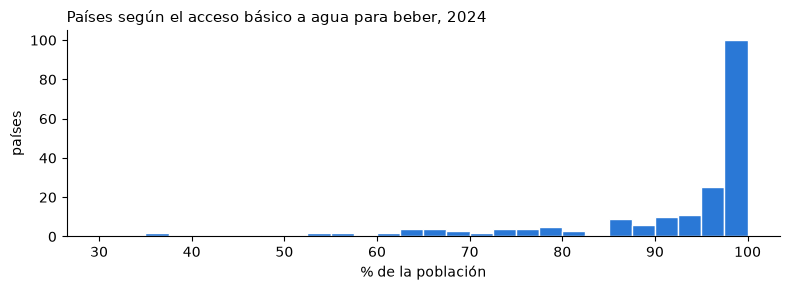

In [16]:
agua_ultimo = panel[(panel["anio"] == HASTA) & panel["agua"].notna() & panel["vida"].notna()]
print(f"{len(agua_ultimo)} países en {HASTA}")
for umbral in [90, 95, 99]:
    print(f"  con {umbral} % o más de acceso básico: {(agua_ultimo['agua'] >= umbral).sum()} ({(agua_ultimo['agua'] >= umbral).mean():.0%})")
altos = agua_ultimo[agua_ultimo["agua"] >= 95]
print(f"Esperanza de vida entre los de 95 % o más: de {altos['vida'].min():.1f} a {altos['vida'].max():.1f} años")

fig, eje = plt.subplots(figsize=(8, 3))
eje.hist(agua_ultimo["agua"], bins=np.arange(30, 102.5, 2.5), color="#2a78d6", edgecolor="white")
eje.set_title(f"Países según el acceso básico a agua para beber, {HASTA}", loc="left", fontsize=11)
eje.set_xlabel("% de la población"); eje.set_ylabel("países")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


Más de la mitad de los países está en el último 5 % del eje, y entre ellos la esperanza de vida varía más de veinte años. En una escala lineal, todos esos puntos quedarían apilados en una franja angosta. Por eso el gráfico 2 **amplía el tramo de 90 % a 100 %**: ocupa casi la mitad del ancho y queda sombreado y rotulado para que no se lea como una escala continua. Un botón permite volver a la escala lineal y comparar.

La vacunación tiene otro problema: los valores son enteros y muchos países comparten el mismo porcentaje, así que en una dispersión se tapan entre sí. Además, el umbral del 95 % es una referencia sanitaria. Por eso el gráfico 3 agrupa los países por tramos de cobertura y los muestra como un enjambre de puntos.

### 1.7 El modelo del primer gráfico

El gráfico 1 compara la esperanza de vida de 2024 con la que «corresponde» al PIB por habitante. Usamos la misma regresión que en el artículo: esperanza de vida = a + b · ln(PIB per cápita). Para obtener exactamente los mismos números redondeamos los datos igual que en el repositorio (vida con dos decimales y PIB sin decimales).

In [17]:
ANIO_MODELO = 2024
corte = (panel[panel["anio"] == ANIO_MODELO].dropna(subset=["vida", "pib"])
         .assign(vida=lambda d: d["vida"].round(2), pib=lambda d: d["pib"].round(0)).copy())
b, a = np.polyfit(np.log(corte["pib"]), corte["vida"], 1)
corte["esperada"] = a + b * np.log(corte["pib"])
corte["brecha"] = corte["vida"] - corte["esperada"]
r2 = 1 - corte["brecha"].var() / corte["vida"].var()
print(f"{len(corte)} países · a = {a:.3f} · b = {b:.4f} · R² = {r2:.4f}")
print(f"Duplicar el PIB por habitante se asocia con {b * np.log(2):.1f} años más de esperanza de vida")

paises_2024 = (corte[["iso3", "pais", "region", "ingreso", "poblacion", "pib", "vida", "esperada", "brecha"]]
               .round({"pib": 0, "vida": 1, "esperada": 1, "brecha": 2})
               .astype({"poblacion": "int64"}).reset_index(drop=True))
modelo = {"a": round(float(a), 4), "b": round(float(b), 4), "r2": round(float(r2), 4)}
paises_2024.sort_values("brecha").iloc[[0, 1, 2, -3, -2, -1]]


195 países · a = 22.849 · b = 5.2554 · R² = 0.7444
Duplicar el PIB por habitante se asocia con 3.6 años más de esperanza de vida


,iso3,pais,region,ingreso,poblacion,pib,vida,esperada,brecha
129,NGA,Nigeria,África subsahariana,Medio bajo,232679478,7994.0,54.6,70.1,-15.44
74,GUY,Guyana,América Latina y el Caribe,Alto,831087,70517.0,70.3,81.5,-11.20
134,NRU,Nauru,Asia oriental y Pacífico,Alto,11947,11958.0,62.3,72.2,-9.91
100,LBN,Líbano,"Medio Oriente, norte de África, Afganistán y P...",Medio bajo,5805962,10469.0,77.9,71.5,6.45
89,JOR,Jordania,"Medio Oriente, norte de África, Afganistán y P...",Medio alto,11552876,10468.0,78.0,71.5,6.49
156,SLB,Islas Salomón,Asia oriental y Pacífico,Medio bajo,819198,2354.0,70.7,63.7,7.04


¿El agua o la vacunación agregan algo al ingreso? Correlacionamos la brecha de cada país (lo que vive de más o de menos según su PIB) con ambos indicadores en 2024:

In [18]:
cruce = corte.dropna(subset=["agua", "sarampion"])
print(f"{len(cruce)} países con los tres datos")
for col in ["agua", "sarampion"]:
    print(f"{col:10} correlación con ln(PIB): {cruce[col].corr(np.log(cruce['pib'])):.2f} · con la brecha: {cruce[col].corr(cruce['brecha']):.2f}")


175 países con los tres datos
agua       correlación con ln(PIB): 0.79 · con la brecha: 0.15
sarampion  correlación con ln(PIB): 0.52 · con la brecha: 0.17


El acceso al agua está muy ligado al ingreso, y una vez que se tiene en cuenta el PIB casi no se relaciona con la brecha. La vacunación está menos atada al ingreso, pero tampoco explica mucho de quién vive más de lo esperado. Lo tenemos en cuenta al leer los gráficos 2 y 3: muestran asociaciones que en buena parte comparten con la riqueza.

## Cómo se muestran los gráficos

Cada gráfico es una página HTML completa (estilos, D3 y datos incluidos) que se muestra dentro de un `iframe` en la salida de la celda. Así funciona igual en Colab, Jupyter o VS Code y los estilos de un gráfico no se mezclan con los del notebook. La página le avisa al notebook cuánto mide para que el marco se ajuste solo. Cada gráfico también se guarda en la carpeta `graficos/` del entorno, por si se lo quiere descargar y abrir en el navegador.

El primer gráfico reutiliza **sin cambios** el CSS, el HTML y el JavaScript del artículo publicado ([`TPFinal/index.html`](https://github.com/za0sec/infovis/blob/main/TPFinal/index.html)). Lo único que cambia es la carga de datos: en vez de leer `datos/paises_2024.csv` y `datos/modelo.json` con `d3.csv`, recibe los datos calculados en este notebook.

In [19]:
#@title Código del artículo: estilos, gráfico de dispersión y funciones comunes { display-mode: "form" }
# Copiado tal cual de TPFinal/index.html (la celda 6.2 comprueba que coincida con el repositorio)
CSS_REPO = r'''
    :root {
      color-scheme: light;
      --pagina: #f9f9f7;
      --superficie: #fcfcfb;
      --texto: #0b0b0b;
      --texto-2: #52514e;
      --texto-3: #898781;
      --grilla: #e1e0d9;
      --eje: #c3c2b7;
      --borde: rgba(11, 11, 11, .10);
      --acento: #256abf;

      --mas-fuerte: #256abf;
      --mas-suave: #86b6ef;
      --neutro: #c9c7bf;
      --menos-suave: #f0a3a2;
      --menos-fuerte: #d03b3b;
      --recta: #52514e;

      --serie-1: #2463a6;
      --serie-2: #9a5b00;
      --serie-3: #7443a1;
    }
    @media (prefers-color-scheme: dark) {
      :root:not([data-theme="light"]) {
        color-scheme: dark;
        --pagina: #0d0d0d;
        --superficie: #1a1a19;
        --texto: #f0efec;
        --texto-2: #c3c2b7;
        --texto-3: #898781;
        --grilla: #2c2c2a;
        --eje: #383835;
        --borde: rgba(255, 255, 255, .10);
        --acento: #6da7ec;
        --mas-fuerte: #6da7ec;
        --mas-suave: #2f5f9c;
        --neutro: #5b5a55;
        --menos-suave: #8f3b3b;
        --menos-fuerte: #e66767;
        --recta: #c3c2b7;
        --serie-1: #6baaff;
        --serie-2: #ffb454;
        --serie-3: #c697f4;
      }
    }
    :root[data-theme="dark"] {
      color-scheme: dark;
      --pagina: #0d0d0d;
      --superficie: #1a1a19;
      --texto: #f0efec;
      --texto-2: #c3c2b7;
      --texto-3: #898781;
      --grilla: #2c2c2a;
      --eje: #383835;
      --borde: rgba(255, 255, 255, .10);
      --acento: #6da7ec;
      --mas-fuerte: #6da7ec;
      --mas-suave: #2f5f9c;
      --neutro: #5b5a55;
      --menos-suave: #8f3b3b;
      --menos-fuerte: #e66767;
      --recta: #c3c2b7;
      --serie-1: #6baaff;
      --serie-2: #ffb454;
      --serie-3: #c697f4;
    }

    :is(#fig-dispersion, #fig-ranking) {
      --mas-fuerte: #194b87;
      --mas-suave: #397ba7;
      --neutro: #8d782c;
      --menos-suave: #b85a3e;
      --menos-fuerte: #9a2935;
    }

    @media (prefers-color-scheme: dark) {
      :root:not([data-theme="light"]) :is(#fig-dispersion, #fig-ranking) {
        --mas-fuerte: #91bfdb;
        --mas-suave: #5585a3;
        --neutro: #ded48f;
        --menos-suave: #b36f59;
        --menos-fuerte: #fc8d59;
      }
    }

    :root[data-theme="dark"] :is(#fig-dispersion, #fig-ranking) {
      --mas-fuerte: #91bfdb;
      --mas-suave: #5585a3;
      --neutro: #ded48f;
      --menos-suave: #b36f59;
      --menos-fuerte: #fc8d59;
    }

    * { box-sizing: border-box; }
    body { margin: 0; background: var(--pagina); color: var(--texto); font: 17px/1.65 system-ui, -apple-system, "Segoe UI", sans-serif; }
    .columna, .ancho { margin-inline: auto; padding-inline: clamp(16px, 3vw, 24px); }
    .columna { max-width: clamp(680px, 72vw, 860px); }
    .ancho { max-width: 1040px; }

    header.columna { padding-top: 56px; padding-bottom: 28px; }
    .volanta { margin: 0 0 18px; color: var(--acento); font-size: 13px; font-weight: 600; letter-spacing: .08em; text-transform: uppercase; }
    h1 { margin: 0; font: 600 clamp(38px, 6vw, 60px)/1.05 "Source Serif 4", Georgia, serif; letter-spacing: -.02em; }
    .bajada { margin: 18px 0 0; color: var(--texto-2); font: 400 clamp(19px, 2.4vw, 23px)/1.45 "Source Serif 4", Georgia, serif; }
    .firma { margin: 26px 0 0; padding: 14px 0 0; border-top: 1px solid var(--grilla); color: var(--texto-3); font-size: 14px; }
    .firma strong { color: var(--texto-2); font-weight: 600; }

    article p { margin: 0 0 1.1em; }
    article .columna > p { text-wrap: pretty; }
    article h2 { margin: 2.2em 0 .6em; font: 600 28px/1.2 "Source Serif 4", Georgia, serif; letter-spacing: -.01em; }
    strong { font-weight: 600; }

    .cifras { display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 1px; margin: clamp(24px, 3vw, 34px) 0 clamp(28px, 4vw, 40px); background: var(--grilla); border: 1px solid var(--grilla); }
    .cifra { padding: clamp(14px, 2vw, 20px); background: var(--superficie); }
    .cifra b { display: block; font-size: clamp(26px, 3.2vw, 34px); font-weight: 600; line-height: 1.1; letter-spacing: -.02em; }
    .cifra span { display: block; margin-top: 6px; color: var(--texto-2); font-size: 14px; line-height: 1.4; text-wrap: pretty; }

    figure.ancho { margin: 40px auto 48px; }
    .tarjeta { padding: 22px 22px 16px; background: var(--superficie); border: 1px solid var(--borde); border-radius: 6px; }
    .grafico-titulo { margin: 0; font-size: 19px; font-weight: 600; line-height: 1.3; }
    :is(#fig-dispersion, #fig-trayectorias) .grafico-titulo { margin: 0; font: 600 19px/1.3 system-ui; }
    .grafico-sub { margin: 4px 0 14px; color: var(--texto-2); font-size: 15px; line-height: 1.45; }
    figcaption { margin-top: 10px; color: var(--texto-3); font-size: 13px; line-height: 1.5; }
    figcaption a { color: inherit; }

    .controles { display: flex; flex-wrap: wrap; gap: 10px 14px; align-items: center; margin-bottom: 12px; font-size: 14px; color: var(--texto-2); }
    .controles label { display: flex; gap: 8px; align-items: center; }
    select { max-width: 100%; min-width: 0; }
    select, input[type="search"] { min-height: 34px; padding: 4px 10px; border: 1px solid var(--eje); border-radius: 6px; background: var(--superficie); color: var(--texto); font: inherit; }
    input[type="search"] { width: 200px; }

    .pasos { display: flex; flex-wrap: wrap; gap: 6px; margin: 0 0 10px; }
    .pasos button { min-height: 34px; padding: 5px 12px; border: 1px solid var(--eje); border-radius: 999px; background: var(--superficie); color: var(--texto-2); font: inherit; font-size: 14px; cursor: pointer; }
    .pasos button:hover { border-color: var(--texto-3); color: var(--texto); }
    .pasos button[aria-pressed="true"] { border-color: var(--texto); background: var(--texto); color: var(--superficie); }
    .pasos button:focus-visible, select:focus-visible, input:focus-visible { outline: 2px solid var(--acento); outline-offset: 2px; }
    #trayectorias [role="slider"]:focus { outline: none; }
    #trayectorias [role="slider"]:focus-visible .recorrido-anual { stroke-width: 3.5; }
    .ayuda-teclado { margin: 0 0 10px; color: var(--texto-2); font-size: 13px; }
    #pasos { gap: 8px; }
    #pasos button {
      display: inline-flex; align-items: center; gap: 8px;
      min-height: 40px; padding: 6px 13px; border-radius: 10px;
    }
    #pasos button::before {
      content: ""; width: 9px; height: 9px; flex: none;
      border-radius: 50%; background: var(--color-paso);
    }
    #pasos button[aria-pressed="true"] {
      border-color: var(--color-paso);
      background: color-mix(in srgb, var(--color-paso) 15%, var(--superficie));
      color: var(--texto); font-weight: 600;
    }
    .controles-dispersion { gap: 10px; align-items: stretch; }
    .controles-dispersion label { display: grid; gap: 4px; flex: 1 1 210px; min-width: 0; }
    .controles-dispersion label span { font-size: 13px; font-weight: 600; }
    .controles-dispersion input, .controles-dispersion select {
      width: 100%; min-height: 42px; padding: 8px 12px; border-radius: 10px;
      background: var(--pagina);
    }
    .leyenda { display: flex; flex-wrap: wrap; gap: 6px 16px; margin: 0 0 6px; color: var(--texto-2); font-size: 13px; }
    .leyenda span { display: inline-flex; gap: 6px; align-items: center; }
    .leyenda i { width: 10px; height: 10px; border-radius: 50%; }
    .leyenda i.linea { width: 16px; height: 0; border-top: 1.5px solid var(--recta); border-radius: 0; }

    .lienzo { position: relative; }
    .lienzo svg { display: block; width: 100%; height: auto; overflow: visible; }
    .eje text { fill: var(--texto-3); font-size: 12px; font-variant-numeric: tabular-nums; }
    .eje line, .eje path { stroke: var(--eje); }
    .eje .domain, .eje-referencia { stroke: var(--texto-3); stroke-width: 1.2; }
    .grilla line { stroke: var(--grilla); }
    .titulo-eje { fill: var(--texto-2); font-size: 12px; font-weight: 700; }
    .etiqueta { fill: var(--texto); font-size: 12px; font-weight: 600; paint-order: stroke; stroke: var(--superficie); stroke-width: 4px; stroke-linejoin: round; pointer-events: none; }
    .etiqueta.suave { fill: var(--texto-2); font-weight: 400; }

    .tooltip { position: absolute; z-index: 5; min-width: min(190px, 100%); max-width: 100%; padding: 10px 12px; background: var(--superficie); border: 1px solid var(--borde); border-radius: 6px; box-shadow: 0 6px 20px rgba(0, 0, 0, .14); font-size: 13px; line-height: 1.45; pointer-events: none; opacity: 0; transition: opacity .12s; }
    .tooltip.visible { opacity: 1; }
    .tooltip .t-pais { font-size: 14px; font-weight: 600; }
    .tooltip .t-region { margin-bottom: 6px; color: var(--texto-3); font-size: 12px; }
    .tooltip dl { display: grid; grid-template-columns: auto auto; gap: 1px 14px; margin: 0; }
    .tooltip dt { color: var(--texto-2); }
    .tooltip dd { margin: 0; font-weight: 600; text-align: right; font-variant-numeric: tabular-nums; }
    :is(#dispersion, #ranking, #trayectorias) .tooltip { position: static; opacity: 1; width: 280px; min-width: 0; max-width: 100%; margin: 10px 0 0 auto; padding: 10px 12px; box-shadow: none; }
    #ranking .ficha-ranking.interior { position: absolute; right: 0; bottom: 16px; margin: 0; }
    #ranking .ficha-ranking { width: 250px; }
    #trayectorias .ficha-ranking.interior { position: absolute; right: 14px; bottom: 60px; margin: 0; }
    .tooltip .t-region, .ficha-pais .t-contexto { margin: 2px 0 7px; color: var(--texto-2); font-size: 12px; }
    .tooltip .t-unidad { margin-top: 7px; color: var(--texto-2); font-size: 11px; }
    :is(#ranking, #trayectorias) .tooltip dl { grid-template-columns: minmax(0, 1fr) auto; gap: 4px 10px; }
    #ranking .tooltip dl { font-size: 12px; }
    #dispersion .ficha-pais dl { grid-template-columns: 1fr; gap: 4px; }
    .ficha-pais dl > div { display: grid; grid-template-columns: minmax(0, 1fr) auto; gap: 10px; align-items: baseline; }
    #dispersion .ficha-pais { position: absolute; margin: 0; }
    #dispersion.ficha-estrecha .ficha-pais { width: 100%; padding: 8px 10px; font-size: 12px; }
    @media (max-width: 640px) {
      :is(#ranking, #trayectorias) .tooltip { width: 100%; }
    }

    .controles input[type="checkbox"] { width: 16px; height: 16px; margin: 0; accent-color: var(--acento); }
    .nombre-fila { fill: var(--texto); font-size: 13px; }
    .nombre-fila.argentina { font-weight: 700; }
    .valor-fila { fill: var(--texto-2); font-size: 12px; font-variant-numeric: tabular-nums; }
    .nota-grafico { margin: 8px 0 0; color: var(--texto-2); font-size: 14px; }

    .resumen { display: flex; flex-wrap: wrap; gap: 8px 22px; margin: 6px 0 0; padding: 0; list-style: none; color: var(--texto-2); font-size: 14px; }
    .resumen li { display: flex; gap: 8px; align-items: baseline; }
    .resumen i { flex: none; width: 14px; height: 0; border-top: 2px solid; transform: translateY(-4px); }
    .resumen b { color: var(--texto); font-weight: 600; }
    .lista { margin: 0 0 1.1em; padding-left: 1.2em; }
    .lista li { margin-bottom: .3em; }
    code { font: 13px/1 ui-monospace, SFMono-Regular, Menlo, monospace; color: var(--texto-2); }
    .leyenda i.trazo { width: 16px; height: 0; border-top: 2px solid; border-radius: 0; }
    #trayectorias .anio { font-size: 11px; }

    details.tabla { margin-top: 14px; font-size: 14px; }
    details.tabla summary { cursor: pointer; color: var(--acento); font-weight: 600; }
    .tabla-scroll { max-height: 420px; margin-top: 10px; overflow: auto; border: 1px solid var(--grilla); border-radius: 6px; }
    table { width: 100%; border-collapse: collapse; font-variant-numeric: tabular-nums; }
    th, td { padding: 6px 10px; border-bottom: 1px solid var(--grilla); text-align: right; white-space: nowrap; }
    th:first-child, td:first-child { text-align: left; }
    th { position: sticky; top: 0; background: var(--superficie); color: var(--texto-2); font-weight: 600; cursor: pointer; user-select: none; }
    th[aria-sort="ascending"]::after { content: " ↑"; }
    th[aria-sort="descending"]::after { content: " ↓"; }

    footer { margin-top: 64px; padding: 28px 0 60px; border-top: 1px solid var(--grilla); color: var(--texto-3); font-size: 14px; }
    a { color: var(--acento); }

    @media (max-width: 640px) {
      body { font-size: 16px; }
      header.columna { padding-top: 36px; }
      .cifras { grid-template-columns: 1fr; }
      .tarjeta { padding: 16px 12px 12px; }
      input[type="search"] { width: 100%; }
      .controles label { flex: 1 1 100%; min-width: 0; }
      .controles select { flex: 1; }
    }
'''

FIGURA_DISPERSION = r'''
    <figure class="ancho" id="fig-dispersion">
      <div class="tarjeta">
        <h2 class="grafico-titulo">¿Los países con mayor ingreso viven más?</h2>
        <p class="grafico-sub">El área de cada círculo es proporcional a la población de la economía. La línea marca la esperanza de vida que «corresponde» a cada nivel de ingreso; el color indica cuánto se aleja cada país de ella.</p>
        <div class="pasos" id="pasos" aria-label="Recorrido guiado por el gráfico"></div>
        <div class="controles controles-dispersion">
          <label><span>Buscar un país</span><input type="search" id="buscar" list="lista-paises" placeholder="Ej.: Argentina" autocomplete="off"></label>
          <datalist id="lista-paises"></datalist>
          <label><span>Filtrar por región</span>
            <select id="region">
              <option value="">Todas</option>
            </select>
          </label>
        </div>
        <div class="leyenda" id="leyenda-brecha"></div>
        <div class="lienzo" id="dispersion"><div class="tooltip ficha-pais" role="status" aria-live="polite" aria-atomic="true"></div></div>
      </div>
      <figcaption>Esperanza de vida al nacer y PIB per cápita en paridad de poder adquisitivo (dólares internacionales constantes de 2021), 2024. El eje horizontal es logarítmico: cada marca duplica o multiplica el ingreso. Fuente: Banco Mundial, World Development Indicators, vía Data360.</figcaption>
    </figure>
'''

JS_COMUN = r'''
    const fmt = {
      anios: d3.format(".1f"),
      dinero: v => d3.format(",.0f")(v).replace(/,/g, "."),
      pob: v => v >= 1e6 ? d3.format(".1f")(v / 1e6).replace(".", ",") + " millones" : d3.format(",.0f")(v).replace(/,/g, ".") + " hab.",
      signo: v => (v > 0 ? "+" : v < 0 ? "−" : "") + d3.format(".1f")(Math.abs(v)).replace(".", ","),
      coma: v => String(v).replace(".", ","),
      porcentaje: v => fmt.coma((v * 100).toFixed(1)) + " %",
    };

    const CLASES = [
      { min: 4, nombre: "4 años o más por encima", token: "--mas-fuerte" },
      { min: 1.5, nombre: "1,5 a 4 por encima", token: "--mas-suave" },
      { min: -1.5, nombre: "Cerca de lo esperado", token: "--neutro" },
      { min: -4, nombre: "1,5 a 4 por debajo", token: "--menos-suave" },
      { min: -Infinity, nombre: "4 años o más por debajo", token: "--menos-fuerte" },
    ];
    const claseDe = brecha => CLASES.find(c => brecha >= c.min);
    const colorBrecha = d => `var(${claseDe(d.brecha).token})`;

    function leyendaBrechas(selector) {
      const leyenda = d3.select(selector);
      leyenda.selectAll("span").data(CLASES).join("span")
        .call(s => s.append("i").style("background", c => `var(${c.token})`))
        .call(s => s.append("span").text(c => c.nombre));
      return leyenda;
    }

    function tooltip(contenedor, fija = false) {
      const el = contenedor.querySelector(".tooltip");
      if (fija) el.classList.add("ficha-ranking");
      return {
        mostrar(filas, titulo, subtitulo, x, y, unidad = "") {
          el.replaceChildren();
          const t = document.createElement("div"); t.className = "t-pais"; t.textContent = titulo;
          const s = document.createElement("div"); s.className = "t-region"; s.textContent = subtitulo;
          const dl = document.createElement("dl");
          for (const [k, v] of filas) {
            const dt = document.createElement("dt"); dt.textContent = k;
            const dd = document.createElement("dd"); dd.textContent = v;
            dl.append(dt, dd);
          }
          el.append(t, s, dl);
          if (unidad) {
            const nota = document.createElement("div"); nota.className = "t-unidad"; nota.textContent = unidad;
            el.append(nota);
          }
          if (fija) {
            const svg = contenedor.querySelector("svg");
            el.classList.toggle("interior", contenedor.clientWidth >= 900 && svg?.getBoundingClientRect().height > el.offsetHeight + 40);
            if (el.classList.contains("interior")) {
              const caja = el.getBoundingClientRect();
              const tapaDatos = [...svg.querySelectorAll("path, text, circle")].some(marca => {
                if (marca.getAttribute("opacity") === "0") return false;
                const r = marca.getBoundingClientRect();
                if (!(r.right > caja.left && r.left < caja.right && r.bottom > caja.top && r.top < caja.bottom)) return false;
                if (marca.tagName.toLowerCase() !== "path" || contenedor.id !== "trayectorias") return true;
                // La caja de una trayectoria abarca también espacio vacío: comprobar el trazo real.
                const longitud = marca.getTotalLength(), matriz = marca.getScreenCTM();
                for (let distancia = 0; distancia <= longitud + 4; distancia += 4) {
                  const punto = marca.getPointAtLength(Math.min(distancia, longitud)).matrixTransform(matriz);
                  if (punto.x >= caja.left - 2 && punto.x <= caja.right + 2 && punto.y >= caja.top - 2 && punto.y <= caja.bottom + 2) return true;
                }
                return false;
              });
              if (tapaDatos) el.classList.remove("interior");
            }
            return;
          }
          const ancho = contenedor.clientWidth, w = el.offsetWidth, h = el.offsetHeight;
          el.style.left = Math.max(0, Math.min(x + 14, ancho - w)) + "px";
          el.style.top = Math.max(0, y - h - 12) + "px";
          el.classList.add("visible");
        },
        ocultar() { if (!fija) el.classList.remove("visible"); },
      };
    }

    function redibujarAlCambiarAncho(el, dibujar) {
      let ancho = el.clientWidth, espera;
      new ResizeObserver(() => {
        if (el.clientWidth === ancho) return;
        ancho = el.clientWidth;
        clearTimeout(espera);
        espera = setTimeout(dibujar, 120);
      }).observe(el);
    }

'''

JS_DISPERSION = r'''
    function dispersion(paises, modelo) {
      const contenedor = document.getElementById("dispersion");
      const ficha = contenedor.querySelector(".ficha-pais");
      let ultimaFicha = null;
      let areaFicha;
      function ubicarFicha() {
        if (!areaFicha) return;
        const estrecho = contenedor.clientWidth < 500;
        contenedor.classList.toggle("ficha-estrecha", estrecho);
        if (estrecho) {
          ficha.style.maxWidth = "100%";
          ficha.style.left = "0";
          ficha.style.top = "0";
          contenedor.style.paddingTop = `${ficha.offsetHeight + 8}px`;
          return;
        }
        contenedor.style.paddingTop = "";
        const { left, top, right, bottom } = areaFicha;
        ficha.style.maxWidth = `${right - left}px`;
        ficha.style.left = `${right - ficha.offsetWidth}px`;
        ficha.style.top = `${Math.max(top, bottom - ficha.offsetHeight)}px`;
      }
      function actualizarFicha(d = null, contexto = "") {
        const clave = `${d?.iso3 ?? ""}|${contexto}`;
        if (clave === ultimaFicha) return;
        ultimaFicha = clave;
        ficha.replaceChildren();
        const titulo = document.createElement("div");
        titulo.className = "t-pais";
        titulo.textContent = d?.pais ?? "Explorá un país";
        const detalle = document.createElement("p");
        detalle.className = "t-contexto";
        detalle.textContent = d ? [d.region, contexto].filter(Boolean).join(" · ") : "Pasá por un punto o buscá un país.";
        ficha.append(titulo, detalle);
        if (!d) { ubicarFicha(); return; }
        const dl = document.createElement("dl");
        const brecha = fmt.signo(d.brecha) + " años";
        for (const [etiqueta, valor, clase] of [
          ["Brecha del modelo", brecha, "dato-brecha"],
          ["Esperanza de vida", d ? fmt.coma(fmt.anios(d.vida)) + " años" : "—", ""],
          ["PIB por habitante", fmt.dinero(d.pib), ""],
          ["Población", d ? fmt.pob(d.poblacion) : "—", ""],
        ]) {
          const grupo = document.createElement("div"); grupo.className = clase;
          const dt = document.createElement("dt"); dt.textContent = etiqueta;
          const dd = document.createElement("dd"); dd.textContent = valor;
          grupo.append(dt, dd); dl.append(grupo);
        }
        const unidad = document.createElement("div"); unidad.className = "t-unidad"; unidad.textContent = "PIB en PPA · $ internacionales de 2021";
        ficha.append(dl, unidad);
        ubicarFicha();
      }
      const tip = { ocultar: () => actualizarFicha() };
      const buscar = document.getElementById("buscar");
      const region = document.getElementById("region");
      // Posición de la etiqueta respecto del círculo para evitar choques en la zona más poblada
      const DESTACADOS = { USA: "der", CRI: "der", CHL: "arriba", JPN: "der", NGA: "der", RUS: "der", ARG: "der",
                           ZAF: "der", GNQ: "der", LKA: "izq", IND: "der" };
      const DESTACADOS_MOVIL = { USA: "abajo", CRI: "izq", NGA: "der" };

      d3.select("#lista-paises").selectAll("option").data(paises.map(d => d.pais).sort(d3.ascending))
        .join("option").attr("value", d => d);
      d3.select(region).selectAll("option.r").data([...new Set(paises.map(d => d.region))].sort(d3.ascending))
        .join("option").attr("class", "r").attr("value", d => d).text(d => d);

      const leyenda = leyendaBrechas("#leyenda-brecha");
      leyenda.append("span").call(s => s.append("i").attr("class", "linea"))
        .call(s => s.append("span").text("Esperada según el ingreso"));

      const PASOS = [
        {
          boton: "La regla",
          color: "--recta",
          activo: () => true,
        },
        {
          boton: "Por encima",
          color: "--mas-fuerte",
          activo: d => d.brecha >= 3,
          etiquetas: { JOR: "arriba", LKA: "izq", JPN: "der", CRI: "der", CHL: "arriba", BGD: "izq", ECU: "abajo" },
          movil: { JOR: "arriba", LKA: "izq", JPN: "izq", CRI: "izq" },
        },
        {
          boton: "Cerca de lo esperado",
          color: "--neutro",
          activo: d => claseDe(d.brecha).token === "--neutro",
          etiquetas: { ARG: "der", BRA: "abajo", DEU: "der", IND: "der", MMR: "izq" },
          movil: { ARG: "der", IND: "der", MMR: "izq" },
        },
        {
          boton: "Por debajo",
          color: "--menos-fuerte",
          activo: d => d.brecha <= -2.95,
          etiquetas: { NGA: "der", ZAF: "der", GNQ: "der", RUS: "der", USA: "der", TCD: "izq", AGO: "abajo" },
          movil: { NGA: "der", RUS: "izq", USA: "abajo" },
        },
      ];
      let paso = 0;
      const botones = d3.select("#pasos").selectAll("button").data(PASOS).join("button")
        .attr("type", "button").text(p => p.boton)
        .style("--color-paso", p => `var(${p.color})`)
        .on("click", (ev, p) => { irAPaso(PASOS.indexOf(p)); });
      function irAPaso(i) {
        paso = i;
        botones.attr("aria-pressed", (p, j) => j === paso);
        if (paso !== null) { seleccion = null; buscar.value = ""; region.value = ""; tip.ocultar(); }
        dibujar();
      }

      let seleccion = null;

      function dibujar() {
        const ancho = contenedor.clientWidth;
        const angosto = ancho < 560;
        const alto = Math.round(Math.max(340, Math.min(560, ancho * 0.58)));
        const actual = paso === null ? null : PASOS[paso];
        const m = { top: 24, right: 14, bottom: 46, left: 60 };

        const x = d3.scaleLog().domain([700, 150000]).range([m.left, ancho - m.right]).clamp(true);
        const y = d3.scaleLinear().domain([50, 88]).range([alto - m.bottom, m.top]);
        const r = d3.scaleSqrt().domain([0, d3.max(paises, d => d.poblacion)]).range([0, angosto ? 22 : 34]);
        const radio = d => r(d.poblacion);

        d3.select(contenedor).select("svg").remove();
        const svg = d3.select(contenedor).insert("svg", ".tooltip")
          .attr("viewBox", `0 0 ${ancho} ${alto}`)
          .attr("role", "img")
          .attr("aria-label", "Gráfico de dispersión: esperanza de vida según el ingreso por habitante de cada país en 2024");

        const marcas = [1000, 2000, 5000, 10000, 20000, 50000, 100000];
        svg.append("g").attr("class", "grilla")
          .selectAll("line").data(y.ticks(6)).join("line")
          .attr("x1", m.left).attr("x2", ancho - m.right).attr("y1", d => y(d)).attr("y2", d => y(d));
        svg.append("g").attr("class", "eje").attr("transform", `translate(0,${alto - m.bottom})`)
          .call(d3.axisBottom(x).tickValues(angosto ? [1000, 5000, 20000, 100000] : marcas)
            .tickFormat(v => v >= 1000 ? (v / 1000) + " mil" : v).tickSizeOuter(0));
        svg.append("g").attr("class", "eje").attr("transform", `translate(${m.left},0)`)
          .call(d3.axisLeft(y).ticks(6).tickSizeInner(4).tickSizeOuter(0).tickPadding(6));
        svg.append("text").attr("class", "titulo-eje").attr("x", (m.left + ancho - m.right) / 2).attr("y", alto - 8).attr("text-anchor", "middle")
          .text("PIB por habitante (PPA, escala log)");
        svg.append("text").attr("class", "titulo-eje").attr("text-anchor", "middle")
          .attr("transform", `translate(14,${(m.top + alto - m.bottom) / 2}) rotate(-90)`)
          .text("Esperanza de vida (años)");

        const curva = d3.range(Math.log(700), Math.log(150000), 0.05).map(l => [Math.exp(l), modelo.a + modelo.b * l]);
        svg.append("path").attr("d", d3.line(d => x(d[0]), d => y(d[1]))(curva))
          .attr("fill", "none").attr("stroke", "var(--recta)")
          .attr("stroke-width", paso === 0 ? 2.5 : 1.5).attr("opacity", paso === 0 ? 1 : .7);

        const filtro = region.value;
        const visibles = filtro ? paises.filter(d => d.region === filtro)
          : actual ? paises.filter(actual.activo) : paises;
        const filtrado = Boolean(filtro) || (paso !== null && paso !== 0);

        svg.append("g").selectAll("circle").data(visibles).join("circle")
          .attr("cx", d => x(d.pib)).attr("cy", d => y(d.vida)).attr("r", radio)
          .attr("fill", colorBrecha)
          .attr("fill-opacity", d => !seleccion || d.iso3 === seleccion.iso3 ? .88 : .12);

        const posiciones = actual?.etiquetas ? (angosto ? actual.movil : actual.etiquetas) : (angosto && !filtro ? DESTACADOS_MOVIL : DESTACADOS);
        const etiquetados = seleccion ? [seleccion]
          : actual?.etiquetas ? Object.keys(posiciones).map(iso3 => visibles.find(d => d.iso3 === iso3)).filter(Boolean)
          : visibles.filter(d => (filtro ? Math.abs(d.brecha) >= 3 : d.iso3 in DESTACADOS))
              .filter(d => !angosto || d.iso3 in DESTACADOS_MOVIL || filtro);
        const ocupadas = [];
        svg.append("g").selectAll("text").data(etiquetados).join("text")
          .attr("class", "etiqueta")
          .text(d => d.pais)
          .each(function (d) {
            const etiqueta = d3.select(this);
            const radioPunto = radio(d);
            const lados = new Set([posiciones[d.iso3] || "der", "der", "izq", "arriba", "abajo"]);
            for (const lado of lados) {
              etiqueta
                .attr("x", x(d.pib) + (({ der: radioPunto + 5, izq: -radioPunto - 5 })[lado] ?? 0))
                .attr("y", y(d.vida) + (({ arriba: -radioPunto - 6, abajo: radioPunto + 14 })[lado] ?? 4))
                .attr("text-anchor", ({ der: "start", izq: "end" })[lado] ?? "middle");
              const caja = this.getBBox();
              const cabe = caja.x >= 2 && caja.x + caja.width <= ancho - 2 &&
                caja.y >= m.top && caja.y + caja.height <= alto - m.bottom;
              const choca = ocupadas.some(o => caja.x < o.x + o.width + 5 && caja.x + caja.width + 5 > o.x &&
                caja.y < o.y + o.height + 5 && caja.y + caja.height + 5 > o.y);
              if (cabe && !choca) {
                ocupadas.push(caja);
                return;
              }
            }
            etiqueta.remove();
          });

        areaFicha = { left: m.left + 8, top: m.top + 8, right: ancho - m.right - 8, bottom: alto - m.bottom - 8 };
        const anillo = svg.append("circle").attr("class", "punto-consultado").attr("fill", "none").attr("stroke", "var(--texto)").attr("stroke-width", 1.5).attr("opacity", 0);

        const delaunay = d3.Delaunay.from(visibles, d => x(d.pib), d => y(d.vida));
        const mostrar = (d) => {
          anillo.attr("cx", x(d.pib)).attr("cy", y(d.vida)).attr("r", Math.max(6.5, radio(d) + 3)).attr("opacity", 1);
          actualizarFicha(d, seleccion && seleccion.iso3 !== d.iso3 ? `Consulta momentánea. Seleccionado: ${seleccion.pais}` : "");
        };
        const restaurarFicha = () => {
          if (seleccion) mostrar(seleccion);
          else { anillo.attr("opacity", 0); tip.ocultar(); }
        };
        svg.append("rect").attr("width", ancho).attr("height", alto).attr("fill", "transparent")
          .on("pointermove click", ev => {
            if (ev.type === "pointermove" && ev.pointerType === "touch") return;
            const [px, py] = d3.pointer(ev);
            if (ev.type === "click" && filtrado) {
              const pulsado = visibles.findLast(d => Math.hypot(x(d.pib) - px, y(d.vida) - py) <= radio(d));
              if (pulsado) mostrar(pulsado);
              else irAPaso(0);
              return;
            }
            const d = visibles[delaunay.find(px, py)];
            if (!d || Math.hypot(x(d.pib) - px, y(d.vida) - py) > 40) { restaurarFicha(); return; }
            mostrar(d);
          })
          .on("pointerleave", ev => { if (ev.pointerType !== "touch") restaurarFicha(); });

        restaurarFicha();
        ubicarFicha();
      }

      // Buscar o filtrar saca al lector del recorrido guiado y lo deja explorar libremente
      const salirDelRecorrido = () => { paso = null; botones.attr("aria-pressed", false); };
      buscar.addEventListener("input", () => {
        const texto = buscar.value.trim().toLowerCase();
        const anterior = seleccion;
        seleccion = paises.find(d => d.pais.toLowerCase() === texto) || null;
        if (seleccion) { region.value = ""; salirDelRecorrido(); }
        if (!texto || seleccion || anterior) dibujar();
        if (!seleccion) tip.ocultar();
      });
      function cambiarRegion() {
        seleccion = null;
        buscar.value = "";
        tip.ocultar();
        salirDelRecorrido();
        dibujar();
      }
      region.addEventListener("change", cambiarRegion);

      irAPaso(0);
      redibujarAlCambiarAncho(contenedor, dibujar);
    }
'''


In [20]:
#@title Funciones para armar y mostrar cada gráfico { display-mode: "form" }
FUENTES = '<link href="https://fonts.googleapis.com/css2?family=Source+Serif+4:opsz,wght@8..60,400;8..60,600&display=swap" rel="stylesheet">'
D3 = '<script src="https://cdnjs.cloudflare.com/ajax/libs/d3/7.9.0/d3.min.js"></script>'
CSS_NOTEBOOK = '''
    body { padding: 4px 0 10px; }
    figure.ancho { margin: 0 auto; }
'''
AVISAR_ALTO = '''<script>
  // Le avisa a la celda del notebook cuánto mide la página para ajustar el alto del marco
  (() => {
    const avisar = () => parent.postMessage({ graficoNotebook: window.name, alto: Math.ceil(document.body.getBoundingClientRect().height) + 2 }, "*");
    new ResizeObserver(avisar).observe(document.body);
    addEventListener("load", avisar);
  })();
</script>'''


def a_json(datos):
    # Sin NaN (JSON no los admite) y sin "</" para no cerrar el <script> antes de tiempo
    return json.dumps(datos, ensure_ascii=False, separators=(",", ":"), allow_nan=False).replace("</", "<\\/")


def pagina(titulo, figura, js, datos, css_extra=""):
    return f'''<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{titulo}</title>
{FUENTES}
{D3}
<style>
{CSS_REPO}{css_extra}{CSS_NOTEBOOK}</style>
</head>
<body>
{figura}
<script>
    const DATOS = {a_json(datos)};
{JS_COMUN}
{js}
</script>
{AVISAR_ALTO}
</body>
</html>
'''


def mostrar(pagina_html, archivo, titulo, alto_inicial):
    Path("graficos").mkdir(exist_ok=True)
    Path("graficos", archivo).write_text(pagina_html, encoding="utf-8")
    nombre = "grafico-" + uuid.uuid4().hex[:8]
    display(HTML(f'''<iframe name="{nombre}" title="{html.escape(titulo)}" srcdoc="{html.escape(pagina_html, quote=True)}"
  style="display:block;width:100%;height:{alto_inicial}px;border:0"></iframe>
<script>
  window.addEventListener("message", ev => {{
    if (!ev.data || ev.data.graficoNotebook !== "{nombre}") return;
    document.querySelector('iframe[name="{nombre}"]').style.height = ev.data.alto + "px";
    try {{ google.colab.output.setIframeHeight(document.body.scrollHeight, true); }} catch (e) {{}}
  }});
</script>'''))


def sin_nan(registros):
    return [{k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in r.items()} for r in registros]


## 2. Gráfico 1 — ¿Los países con mayor ingreso viven más?

En 2024, la esperanza de vida al nacer era de 84 años en Japón y de 54,6 en Nigeria. Una parte grande de esa distancia acompaña al ingreso: los países con mayor PIB por habitante suelen vivir más. El primer gráfico muestra esa regla y, sobre todo, a los países que se apartan de ella.

**Por qué este gráfico.** Una dispersión con el PIB en escala logarítmica muestra la forma de la relación (cada duplicación del ingreso ocupa la misma distancia) y deja ver cada país. La línea es la esperanza de vida que estima el modelo para cada nivel de ingreso, y el color codifica la brecha en cinco clases divergentes: azul por encima de lo esperado, coral por debajo y amarillo cerca de la línea. El área de cada círculo es proporcional a la población.

**Cómo usarlo.**
- Los botones **La regla**, **Por encima**, **Cerca de lo esperado** y **Por debajo** filtran el gráfico y rotulan ejemplos.
- **Buscar un país** lo resalta y fija su ficha (brecha, esperanza de vida, PIB por habitante y población).
- **Filtrar por región** muestra solo esa región y rotula las brechas de al menos 3 años.
- Al pasar el mouse cerca de un punto, la ficha muestra ese país. En pantallas táctiles se toca el punto.

In [21]:
datos_dispersion = {"paises": sin_nan(paises_2024.to_dict("records")), "modelo": modelo}
JS_CARGA_DISPERSION = '''
    // En el artículo estos datos llegan con d3.csv y d3.json; acá vienen del notebook
    const paises = DATOS.paises, modelo = DATOS.modelo;
    paises.sort((a, b) => b.poblacion - a.poblacion);
    dispersion(paises, modelo);
'''
grafico_1 = pagina("¿Los países con mayor ingreso viven más?", FIGURA_DISPERSION,
                   JS_DISPERSION + JS_CARGA_DISPERSION, datos_dispersion)
mostrar(grafico_1, "1_ingreso_y_esperanza_de_vida.html", "Gráfico 1: PIB por habitante y esperanza de vida", 900)


In [22]:
print(f"Duplicar el PIB por habitante: +{modelo['b'] * np.log(2):.1f} años · R² = {modelo['r2']:.1%} · {len(paises_2024)} países")
grandes = paises_2024[paises_2024["poblacion"] >= 1_000_000]
print("\nMayores brechas positivas (países de al menos 1 millón de habitantes):")
display(grandes.nlargest(6, "brecha")[["pais", "region", "pib", "vida", "brecha"]])
print("Mayores brechas negativas:")
display(grandes.nsmallest(6, "brecha")[["pais", "region", "pib", "vida", "brecha"]])
paises_2024[paises_2024["iso3"].isin(["USA", "CRI", "ARG", "CHL"])][["pais", "pib", "vida", "esperada", "brecha"]]


Duplicar el PIB por habitante: +3.6 años · R² = 74.4% · 195 países

Mayores brechas positivas (países de al menos 1 millón de habitantes):


,pais,region,pib,vida,brecha
89,Jordania,"Medio Oriente, norte de África, Afganistán y P...",10468.0,78.0,6.49
100,Líbano,"Medio Oriente, norte de África, Afganistán y P...",10469.0,77.9,6.45
125,Malaui,África subsahariana,1634.0,67.6,5.83
130,Nicaragua,América Latina y el Caribe,7661.0,75.1,5.25
98,Kuwait,"Medio Oriente, norte de África, Afganistán y P...",46664.0,84.6,5.23
104,Sri Lanka,Asia meridional,13793.0,77.7,4.73


Mayores brechas negativas:


,pais,region,pib,vida,brecha
129,Nigeria,África subsahariana,7994.0,54.6,-15.44
70,Guinea Ecuatorial,África subsahariana,14998.0,63.9,-9.47
170,Chad,África subsahariana,2431.0,55.2,-8.58
166,Esuatini,África subsahariana,10386.0,64.3,-7.19
35,Côte d’Ivoire,África subsahariana,6747.0,62.1,-7.08
105,Lesoto,África subsahariana,2698.0,57.8,-6.57


,pais,pib,vida,esperada,brecha
6,Argentina,26772.0,77.5,76.4,1.11
33,Chile,30268.0,81.4,77.1,4.29
42,Costa Rica,27325.0,81.0,76.5,4.46
185,Estados Unidos,75698.0,78.9,81.9,-3.00


**Lectura.** La regla se cumple: el modelo con el PIB per cápita da cuenta de cerca de tres cuartas partes de la variación de la esperanza de vida entre países, y a lo largo de la línea cada duplicación del ingreso se asocia con unos 3,6 años más. Pero la nube es ancha. Costa Rica vive 2,1 años más que Estados Unidos con un tercio de su ingreso, y Chile también lo supera. En el otro extremo, Nigeria queda unos 15 años por debajo de lo que estima el modelo, y casi todas las brechas negativas más grandes corresponden a África subsahariana. Argentina queda prácticamente sobre la línea.

La brecha es una distancia a un promedio, no una nota. Dice qué países se apartan del patrón, pero no por qué. Para buscar pistas miramos dos factores que no dependen solo de la riqueza: el agua y las vacunas.

## 3. Gráfico 2 — Agua para beber y esperanza de vida

Tener una fuente de agua mejorada cerca de casa reduce las enfermedades diarreicas, una de las principales causas de muerte infantil en los países pobres. ¿Viven más los países donde más gente tiene acceso básico al agua? ¿Cambió esa relación entre 2000 y 2024?

**Por qué este gráfico.** Para relacionar dos variables continuas país por país, la dispersión es la forma más directa. El deslizador de años muestra cómo se mueve la nube sin cambiar las escalas, así que un desplazamiento en el gráfico es un cambio en los datos. Como más de la mitad de los países está por encima del 95 %, el tramo de 90 % a 100 % se amplía (ver 1.6). Los puntos tienen todos el mismo tamaño porque acá cada país es una observación de la relación, y se colorean por grupo de ingreso para conectar con el gráfico 1.

**Cómo usarlo.**
- Mové el **deslizador** o tocá **▶** para recorrer los años. Al lado se indica cuántos países aparecen en el año elegido.
- Al pasar sobre un punto, la **ficha** muestra el país, el año, el acceso al agua y la esperanza de vida.
- **Buscar un país** (o hacer clic en su punto) lo fija y dibuja su recorrido desde 2000 hasta el año elegido.
- **Escala lineal** muestra el eje sin el tramo ampliado.

In [23]:
def datos_anuales(col, decimales):
    d = panel[panel["anio"].between(DESDE, HASTA) & panel[col].notna() & panel["vida"].notna()]
    d = d.assign(valor=d[col].round(decimales), vida=d["vida"].round(1))
    info = paises.set_index("iso3").loc[sorted(d["iso3"].unique()), ["pais", "region", "ingreso"]]
    return d, {
        "desde": DESDE, "hasta": HASTA,
        "paises": {iso3: sin_nan([fila])[0] for iso3, fila in info.to_dict("index").items()},
        "filas": [[r.iso3, int(r.anio), float(r.valor), float(r.vida)] for r in d.itertuples()],
    }


def resumen_anual(d, cortes, etiquetas):
    grupos = pd.cut(d["valor"], cortes, labels=etiquetas, right=False)
    tabla = d.groupby(["anio", grupos], observed=False)["vida"].agg(["size", "median"]).unstack()
    tabla.columns = [f"{'países' if m == 'size' else 'mediana vida'} {g}" for m, g in tabla.columns]
    tabla.insert(0, "correlación", d.groupby("anio").apply(lambda x: x["valor"].corr(x["vida"]), include_groups=False))
    tabla.insert(0, "países", d.groupby("anio").size())
    return tabla.round(2)


agua, datos_agua = datos_anuales("agua", 1)
resumen_agua = resumen_anual(agua, [0, 80, 95, 101], ["< 80 %", "80–95 %", "≥ 95 %"])
resumen_agua.loc[[2000, 2005, 2010, 2015, 2020, 2024]]


,países,correlación,países < 80 %,países 80–95 %,países ≥ 95 %,mediana vida < 80 %,mediana vida 80–95 %,mediana vida ≥ 95 %
anio,,,,,,,,
2000,203,0.84,60,57,86,54.80,70.3,75.35
2005,209,0.82,55,56,98,56.80,70.8,76.40
2010,212,0.81,53,53,106,59.70,70.3,76.75
2015,213,0.81,51,48,114,62.30,71.2,77.30
2020,205,0.78,42,47,116,61.65,70.2,77.40
2024,202,0.76,37,40,125,63.80,71.3,78.30


In [24]:
#@title Código de los gráficos con deslizador de años (piezas comunes y gráfico de agua) { display-mode: "form" }
CSS_ANUAL = r'''
    :root {
      --ing-1: #86b6ef;
      --ing-2: #3987e5;
      --ing-3: #1c5cab;
      --ing-4: #0d366b;
    }
    @media (prefers-color-scheme: dark) {
      :root:not([data-theme="light"]) {
        --ing-1: #184f95;
        --ing-2: #2a78d6;
        --ing-3: #6da7ec;
        --ing-4: #b7d3f6;
      }
    }
    :root[data-theme="dark"] {
      --ing-1: #184f95;
      --ing-2: #2a78d6;
      --ing-3: #6da7ec;
      --ing-4: #b7d3f6;
    }

    .con-ficha { display: grid; grid-template-columns: minmax(0, 1fr) 236px; gap: 16px; align-items: start; }
    .con-ficha .ficha-anual { position: static; opacity: 1; width: auto; min-width: 0; margin: 4px 0 0; box-shadow: none; pointer-events: auto; }
    .ficha-anual dl { grid-template-columns: 1fr; gap: 4px; }
    .ficha-anual dl > div { display: grid; grid-template-columns: minmax(0, 1fr) auto; gap: 10px; align-items: baseline; }
    .ficha-anual .t-contexto { margin: 2px 0 7px; color: var(--texto-2); font-size: 12px; }
    .ficha-anual .sin-dato { color: var(--texto-2); font-size: 13px; }
    .controles-anuales .escala { display: grid; gap: 4px; flex: 0 1 auto; }
    .controles-anuales .escala > span { font-size: 13px; font-weight: 600; }
    .controles-anuales .pasos { margin: 0; }

    .deslizador { display: flex; flex-wrap: wrap; align-items: center; gap: 10px 14px; margin: 12px 0 4px; padding-top: 12px; border-top: 1px solid var(--grilla); }
    .deslizador .reproducir { display: inline-flex; align-items: center; justify-content: center; width: 40px; height: 40px; flex: none; border: 1px solid var(--eje); border-radius: 50%; background: var(--superficie); color: var(--texto); font: inherit; font-size: 13px; cursor: pointer; }
    .deslizador .reproducir:hover { border-color: var(--texto-3); }
    .deslizador label { display: flex; flex: 1 1 260px; align-items: center; gap: 10px; color: var(--texto-2); font-size: 13px; font-weight: 600; }
    .deslizador input[type="range"] { flex: 1; min-width: 0; min-height: 32px; margin: 0; accent-color: var(--acento); }
    .deslizador :is(button, input):focus-visible { outline: 2px solid var(--acento); outline-offset: 2px; }
    .anio-actual { min-width: 2.6em; font: 600 28px/1 "Source Serif 4", Georgia, serif; font-variant-numeric: tabular-nums; }
    .conteo { color: var(--texto-2); font-size: 14px; }
    .conteo b { color: var(--texto); font-weight: 600; }
    .resumen-anual { margin: 6px 0 0; color: var(--texto-2); font-size: 14px; text-wrap: pretty; }

    .punto { stroke: var(--superficie); stroke-width: 1; }
    .punto.fuera { stroke-width: 1.6; stroke-dasharray: 2 1.5; }
    .banda-ampliada { fill: var(--grilla); opacity: .45; }
    .corte-escala { stroke: var(--texto-3); stroke-dasharray: 3 3; }
    .nota-eje { fill: var(--texto-3); font-size: 11px; }
    .rastro { fill: none; stroke: var(--texto-2); stroke-width: 1.5; }
    .rastro-punto { fill: var(--superficie); stroke: var(--texto-2); stroke-width: 1.2; }
    .mediana { stroke: var(--texto); stroke-width: 2; stroke-linecap: round; }
    .conteo-banda { fill: var(--texto-2); font-size: 12px; font-variant-numeric: tabular-nums; }
    .leyenda i.mediana-leyenda { width: 16px; height: 0; border-top: 2px solid var(--texto); border-radius: 0; }
    .leyenda i.fuera-leyenda { background: transparent; border: 1.5px dashed var(--texto-2); }

    @media (max-width: 720px) {
      .con-ficha { grid-template-columns: 1fr; }
      .con-ficha .ficha-anual { margin: 0; }
    }
'''

JS_ANUAL = r'''
    // Piezas compartidas por los dos gráficos con deslizador de años
    const INGRESOS = [
      { nombre: "Bajo", token: "--ing-1" },
      { nombre: "Medio bajo", token: "--ing-2" },
      { nombre: "Medio alto", token: "--ing-3" },
      { nombre: "Alto", token: "--ing-4" },
    ];
    const colorIngreso = d => {
      const grupo = INGRESOS.find(g => g.nombre === d.ingreso);
      return grupo ? `var(${grupo.token})` : "var(--texto-3)";
    };
    const VIDA_MIN = 35, VIDA_MAX = 88;
    const fuera = d => d.vida < VIDA_MIN;
    const DURACION = matchMedia("(prefers-reduced-motion: reduce)").matches ? 0 : 450;

    function prepararFilas(datos) {
      const filas = datos.filas.map(([iso3, anio, valor, vida]) => ({ iso3, anio, valor, vida, ...datos.paises[iso3] }));
      return { filas, porAnio: d3.group(filas, d => d.anio), porPais: d3.group(filas, d => d.iso3) };
    }

    function correlacion(filas) {
      const mx = d3.mean(filas, d => d.valor), my = d3.mean(filas, d => d.vida);
      const sxy = d3.sum(filas, d => (d.valor - mx) * (d.vida - my));
      const sxx = d3.sum(filas, d => (d.valor - mx) ** 2), syy = d3.sum(filas, d => (d.vida - my) ** 2);
      return sxy / Math.sqrt(sxx * syy);
    }

    function leyendaIngresos(selector, filas) {
      const grupos = INGRESOS.slice();
      if (filas.some(d => !INGRESOS.some(g => g.nombre === d.ingreso))) grupos.push({ nombre: "Sin clasificar", token: "--texto-3" });
      const leyenda = d3.select(selector);
      leyenda.append("span").attr("class", "titulo-leyenda").text("Ingreso del país:");
      leyenda.selectAll("span.grupo").data(grupos).join("span").attr("class", "grupo")
        .call(s => s.append("i").style("background", g => `var(${g.token})`))
        .call(s => s.append("span").text(g => g.nombre));
      return leyenda;
    }

    function fichaAnual(el, { d, anio, filas, vacia, nota }) {
      el.replaceChildren();
      const titulo = document.createElement("div"); titulo.className = "t-pais";
      const contexto = document.createElement("p"); contexto.className = "t-contexto";
      el.append(titulo, contexto);
      if (!d) {
        titulo.textContent = vacia?.titulo ?? "Explorá un país";
        contexto.textContent = vacia?.texto ?? "Pasá por un punto o buscá un país.";
        return;
      }
      titulo.textContent = d.pais;
      contexto.textContent = [d.region, d.ingreso ? `ingreso ${d.ingreso.toLowerCase()}` : ""].filter(Boolean).join(" · ");
      if (!filas) {
        const sin = document.createElement("p"); sin.className = "sin-dato";
        sin.textContent = `Sin datos de ambos indicadores en ${anio}.`;
        el.append(sin);
        return;
      }
      const dl = document.createElement("dl");
      for (const [etiqueta, valor] of filas) {
        const grupo = document.createElement("div");
        const dt = document.createElement("dt"); dt.textContent = etiqueta;
        const dd = document.createElement("dd"); dd.textContent = valor;
        grupo.append(dt, dd); dl.append(grupo);
      }
      el.append(dl);
      if (nota) {
        const n = document.createElement("div"); n.className = "t-unidad"; n.textContent = nota;
        el.append(n);
      }
    }

    // Deslizador con botón de reproducción. alCambiar(anio, animar) se llama en cada cambio.
    function deslizadorAnual(raiz, desde, hasta, alCambiar) {
      const rango = raiz.querySelector('input[type="range"]');
      const salida = raiz.querySelector(".anio-actual");
      const boton = raiz.querySelector(".reproducir");
      rango.min = desde; rango.max = hasta; rango.step = 1; rango.value = hasta;
      let reloj = null;
      const fijar = (anio, animar = true) => {
        rango.value = anio;
        salida.value = salida.textContent = anio;
        rango.setAttribute("aria-valuetext", String(anio));
        alCambiar(+anio, animar);
      };
      const detener = () => {
        clearInterval(reloj); reloj = null;
        boton.textContent = "▶"; boton.setAttribute("aria-label", "Reproducir la evolución año por año");
      };
      rango.addEventListener("input", () => { detener(); fijar(+rango.value); });
      boton.addEventListener("click", () => {
        if (reloj) { detener(); return; }
        if (+rango.value >= hasta) fijar(desde);
        boton.textContent = "❚❚"; boton.setAttribute("aria-label", "Pausar");
        reloj = setInterval(() => {
          const siguiente = +rango.value + 1;
          if (siguiente > hasta) { detener(); return; }
          fijar(siguiente);
        }, Math.max(DURACION + 250, 500));
      });
      detener();
      return { fijar, actual: () => +rango.value };
    }

    function buscador(input, lista, paises, alElegir) {
      const nombres = [...new Set(paises.map(d => d.pais))].sort((a, b) => a.localeCompare(b, "es"));
      d3.select(lista).selectAll("option").data(nombres).join("option").attr("value", d => d);
      input.addEventListener("input", () => {
        const texto = input.value.trim().toLowerCase();
        const elegido = paises.find(d => d.pais.toLowerCase() === texto);
        if (elegido) alElegir(elegido.iso3);
        else if (!texto) alElegir(null);
      });
    }
'''

FIGURA_AGUA = r'''
    <figure class="ancho" id="fig-agua">
      <div class="tarjeta">
        <h2 class="grafico-titulo">¿Viven más los países donde más gente tiene agua para beber?</h2>
        <p class="grafico-sub">Cada punto es un país. El eje horizontal muestra el porcentaje de la población que usa al menos un servicio básico de agua para beber; el vertical, la esperanza de vida al nacer. Más de la mitad de los países está por encima del 95 %, así que por defecto ese tramo se muestra ampliado.</p>
        <div class="controles controles-dispersion controles-anuales">
          <label><span>Buscar un país</span><input type="search" id="buscar-agua" list="lista-agua" placeholder="Ej.: Argentina" autocomplete="off"></label>
          <datalist id="lista-agua"></datalist>
          <div class="escala"><span>Eje horizontal</span><div class="pasos" id="escala-agua" aria-label="Escala del eje horizontal"></div></div>
        </div>
        <div class="leyenda" id="leyenda-agua"></div>
        <div class="con-ficha">
          <div class="lienzo" id="agua"></div>
          <aside class="tooltip ficha-anual" id="ficha-agua" role="status" aria-live="polite" aria-atomic="true"></aside>
        </div>
        <div class="deslizador" id="anio-agua">
          <button type="button" class="reproducir"></button>
          <label>Año <input type="range" aria-label="Año del gráfico de agua"></label>
          <output class="anio-actual"></output>
          <span class="conteo" id="conteo-agua"></span>
        </div>
        <p class="resumen-anual" id="resumen-agua" aria-live="polite"></p>
      </div>
      <figcaption>Población que usa al menos un servicio básico de agua para beber (% de la población) y esperanza de vida al nacer (años), 2000–2024. Solo se dibujan los países con ambos datos en el año elegido; no se imputan faltantes. Las escalas quedan fijas al mover el año. Los valores de esperanza de vida menores de 35 años se dibujan sobre el borde inferior con un círculo punteado. Fuente: Banco Mundial, World Development Indicators (estimaciones de OMS/UNICEF JMP y Naciones Unidas), vía Data360.</figcaption>
    </figure>
'''

JS_AGUA = r'''
    function graficoAgua(datos) {
      const contenedor = document.getElementById("agua");
      const ficha = document.getElementById("ficha-agua");
      const buscar = document.getElementById("buscar-agua");
      const { filas, porAnio, porPais } = prepararFilas(datos);
      let anio = datos.hasta, ampliada = true, seleccion = null, consultado = null;
      let x, y, svg, capaPuntos, capaRastro, anillo, delaunay = null, visibles = [];

      leyendaIngresos("#leyenda-agua", filas)
        .append("span").call(s => s.append("i").attr("class", "fuera-leyenda"))
        .call(s => s.append("span").text("Esperanza de vida menor de 35 años"));

      const ESCALAS = [
        { boton: "Ampliar 90–100 %", ampliada: true },
        { boton: "Escala lineal", ampliada: false },
      ];
      const botones = d3.select("#escala-agua").selectAll("button").data(ESCALAS).join("button")
        .attr("type", "button").text(e => e.boton)
        .attr("aria-pressed", e => e.ampliada === ampliada)
        .on("click", (ev, e) => { ampliada = e.ampliada; botones.attr("aria-pressed", o => o.ampliada === ampliada); dibujar(); });

      const fmtPct = v => fmt.coma(v.toFixed(1)) + " %";
      const fmtVida = v => fmt.coma(v.toFixed(1)) + " años";

      function mostrarFicha() {
        const iso3 = consultado ?? seleccion;
        if (!iso3) { fichaAnual(ficha, {}); return; }
        const d = porAnio.get(anio)?.find(f => f.iso3 === iso3);
        const pais = d ?? { ...datos.paises[iso3], iso3 };
        fichaAnual(ficha, {
          d: pais, anio,
          filas: d && [
            ["Año", String(anio)],
            ["Acceso básico a agua para beber", fmtPct(d.valor)],
            ["Esperanza de vida", fmtVida(d.vida)],
          ],
          nota: d && fuera(d) ? "Esperanza de vida fuera de la escala del gráfico." : "Agua: % de la población · Vida: años al nacer",
        });
      }

      function dibujar() {
        const ancho = contenedor.clientWidth;
        const angosto = ancho < 560;
        const alto = Math.round(Math.max(340, Math.min(540, ancho * 0.62)));
        const m = { top: 24, right: 16, bottom: 46, left: 56 };
        const izq = m.left, der = ancho - m.right;
        x = ampliada
          ? d3.scaleLinear().domain([15, 90, 100]).range([izq, izq + (der - izq) * 0.55, der])
          : d3.scaleLinear().domain([15, 100]).range([izq, der]);
        y = d3.scaleLinear().domain([VIDA_MIN, VIDA_MAX]).range([alto - m.bottom, m.top]).clamp(true);

        d3.select(contenedor).select("svg").remove();
        svg = d3.select(contenedor).append("svg")
          .attr("viewBox", `0 0 ${ancho} ${alto}`)
          .attr("role", "img")
          .attr("aria-label", "Gráfico de dispersión: acceso básico a agua para beber y esperanza de vida por país, con un deslizador de años");

        if (ampliada) {
          svg.append("rect").attr("class", "banda-ampliada")
            .attr("x", x(90)).attr("y", m.top).attr("width", x(100) - x(90)).attr("height", alto - m.bottom - m.top);
          svg.append("line").attr("class", "corte-escala")
            .attr("x1", x(90)).attr("x2", x(90)).attr("y1", m.top).attr("y2", alto - m.bottom);
          svg.append("text").attr("class", "nota-eje").attr("x", x(90) + 6).attr("y", m.top + 12)
            .text(angosto ? "Tramo ampliado" : "Tramo ampliado: 90 % a 100 %");
        }
        svg.append("g").attr("class", "grilla")
          .selectAll("line").data(y.ticks(6)).join("line")
          .attr("x1", izq).attr("x2", der).attr("y1", d => y(d)).attr("y2", d => y(d));
        const marcas = ampliada
          ? (angosto ? [20, 50, 90, 95, 100] : [20, 40, 60, 80, 90, 92, 94, 96, 98, 100])
          : (angosto ? [20, 40, 60, 80, 100] : [20, 30, 40, 50, 60, 70, 80, 90, 100]);
        svg.append("g").attr("class", "eje").attr("transform", `translate(0,${alto - m.bottom})`)
          .call(d3.axisBottom(x).tickValues(marcas).tickFormat(v => v + " %").tickSizeOuter(0));
        svg.append("g").attr("class", "eje").attr("transform", `translate(${izq},0)`)
          .call(d3.axisLeft(y).ticks(6).tickSizeInner(4).tickSizeOuter(0).tickPadding(6));
        svg.append("text").attr("class", "titulo-eje").attr("x", (izq + der) / 2).attr("y", alto - 8).attr("text-anchor", "middle")
          .text(angosto ? "Acceso básico a agua (% de la población)" : "Población que usa al menos un servicio básico de agua para beber (%)");
        svg.append("text").attr("class", "titulo-eje").attr("text-anchor", "middle")
          .attr("transform", `translate(14,${(m.top + alto - m.bottom) / 2}) rotate(-90)`)
          .text("Esperanza de vida (años)");

        capaRastro = svg.append("g");
        capaPuntos = svg.append("g");
        anillo = svg.append("circle").attr("fill", "none").attr("stroke", "var(--texto)").attr("stroke-width", 1.5).attr("opacity", 0);
        svg.append("g").attr("class", "etiquetas");

        svg.append("rect").attr("width", ancho).attr("height", alto).attr("fill", "transparent")
          .on("pointermove click", ev => {
            const [px, py] = d3.pointer(ev);
            const i = delaunay?.find(px, py);
            const d = i === undefined ? null : visibles[i];
            const cerca = d && Math.hypot(x(d.valor) - px, y(d.vida) - py) <= 30;
            if (ev.type === "click") {
              elegir(cerca ? (seleccion === d.iso3 ? null : d.iso3) : null);
              return;
            }
            if (ev.pointerType === "touch") return;
            consultado = cerca ? d.iso3 : null;
            marcar();
          })
          .on("pointerleave", () => { consultado = null; marcar(); });

        actualizar(false);
      }

      function radio() { return contenedor.clientWidth < 560 ? 4 : 5; }

      function actualizar(animar) {
        visibles = (porAnio.get(anio) ?? []).slice().sort((a, b) => d3.ascending(a.iso3, b.iso3));
        const t = svg.transition().duration(animar ? DURACION : 0);
        capaPuntos.selectAll("circle").data(visibles, d => d.iso3).join(
          entra => entra.append("circle").attr("class", "punto")
            .attr("cx", d => x(d.valor)).attr("cy", d => y(d.vida)).attr("r", 0)
            .call(e => e.transition(t).attr("r", radio())),
          act => act.call(a => a.transition(t).attr("cx", d => x(d.valor)).attr("cy", d => y(d.vida)).attr("r", radio())),
          sale => sale.call(s => s.transition(t).attr("r", 0).remove()),
        )
          .classed("fuera", fuera)
          .attr("fill", colorIngreso)
          .style("stroke", d => fuera(d) ? colorIngreso(d) : null);
        delaunay = d3.Delaunay.from(visibles, d => x(d.valor), d => y(d.vida));

        document.getElementById("conteo-agua").innerHTML = "";
        d3.select("#conteo-agua").call(s => s.append("b").text(visibles.length)).append("span").text(" países con ambos datos");
        resumir();
        marcar(animar);
      }

      function resumir() {
        const bajo = visibles.filter(d => d.valor < 80), alto = visibles.filter(d => d.valor >= 95);
        const partes = [`En ${anio}, la correlación entre ambas variables fue de ${fmt.coma(correlacion(visibles).toFixed(2))}.`];
        if (bajo.length && alto.length) {
          partes.push(`La mediana de la esperanza de vida fue de ${fmtVida(d3.median(bajo, d => d.vida))} en los ${bajo.length} países donde menos del 80 % de la población tiene acceso básico y de ${fmtVida(d3.median(alto, d => d.vida))} en los ${alto.length} donde lo tiene el 95 % o más.`);
        }
        document.getElementById("resumen-agua").textContent = partes.join(" ");
      }

      function marcar(animar = false) {
        const foco = consultado ?? seleccion;
        capaPuntos.selectAll("circle").attr("fill-opacity", d => fuera(d) ? 0 : (!seleccion || d.iso3 === seleccion ? .88 : .2));
        const d = foco && visibles.find(v => v.iso3 === foco);
        if (d) anillo.attr("cx", x(d.valor)).attr("cy", y(d.vida)).attr("r", radio() + 3).attr("opacity", 1);
        else anillo.attr("opacity", 0);

        // Recorrido del país seleccionado desde 2000 hasta el año elegido
        const rastro = seleccion ? (porPais.get(seleccion) ?? []).filter(f => f.anio <= anio) : [];
        capaRastro.selectAll("path").data(rastro.length > 1 ? [rastro] : []).join("path").attr("class", "rastro")
          .attr("d", d3.line(f => x(f.valor), f => y(f.vida)));
        capaRastro.selectAll("circle").data(rastro.filter(f => f.anio < anio)).join("circle").attr("class", "rastro-punto")
          .attr("r", 2).attr("cx", f => x(f.valor)).attr("cy", f => y(f.vida));

        const etiquetado = seleccion ? visibles.find(v => v.iso3 === seleccion) : null;
        const ancho = contenedor.clientWidth;
        svg.select(".etiquetas").selectAll("text").data(etiquetado ? [etiquetado] : []).join("text")
          .attr("class", "etiqueta").text(e => e.pais)
          .attr("x", e => x(e.valor) + (x(e.valor) > ancho - 120 ? -radio() - 6 : radio() + 6))
          .attr("text-anchor", e => x(e.valor) > ancho - 120 ? "end" : "start")
          .attr("y", e => y(e.vida) - radio() - 4);
        mostrarFicha();
      }

      function elegir(iso3) {
        seleccion = iso3;
        consultado = null;
        if (!iso3) buscar.value = "";
        else buscar.value = datos.paises[iso3].pais;
        marcar();
      }

      buscador(buscar, document.getElementById("lista-agua"),
        Object.entries(datos.paises).map(([iso3, p]) => ({ iso3, ...p })).filter(p => porPais.has(p.iso3)), elegir);
      deslizadorAnual(document.getElementById("anio-agua"), datos.desde, datos.hasta, (a, animar) => {
        anio = a;
        if (svg) actualizar(animar);
      }).fijar(datos.hasta, false);
      dibujar();
      redibujarAlCambiarAncho(contenedor, dibujar);
    }

    graficoAgua(DATOS);
'''


In [25]:
grafico_2 = pagina("Agua para beber y esperanza de vida", FIGURA_AGUA, JS_ANUAL + JS_AGUA, datos_agua, CSS_ANUAL)
mostrar(grafico_2, "2_agua_y_esperanza_de_vida.html", "Gráfico 2: acceso básico al agua y esperanza de vida", 980)


In [26]:
cambios = (agua[agua["anio"].isin([DESDE, HASTA])].pivot(index="pais", columns="anio", values=["valor", "vida"]).dropna())
cambios = pd.DataFrame({"agua_2000": cambios[("valor", DESDE)], "agua_2024": cambios[("valor", HASTA)],
                        "vida_2000": cambios[("vida", DESDE)], "vida_2024": cambios[("vida", HASTA)]})
cambios["más agua"] = cambios["agua_2024"] - cambios["agua_2000"]
cambios["más años"] = cambios["vida_2024"] - cambios["vida_2000"]
print(f"{len(cambios)} países con datos en {DESDE} y {HASTA}")
print(f"Correlación entre lo que ganó cada país en acceso al agua y en esperanza de vida: {cambios['más agua'].corr(cambios['más años']):.2f}")
display(cambios.nlargest(6, "más agua").round(1))
ultimo_agua = agua[(agua["anio"] == HASTA) & (agua["valor"] >= 95)]
print(f"Esperanza de vida más baja entre los países con 95 % o más de acceso en {HASTA}:")
ultimo_agua.nsmallest(5, "vida")[["pais", "valor", "vida", "ingreso"]]


191 países con datos en 2000 y 2024
Correlación entre lo que ganó cada país en acceso al agua y en esperanza de vida: 0.51


,agua_2000,agua_2024,vida_2000,vida_2024,más agua,más años
pais,,,,,,
Afganistán,29.7,80.8,55.0,66.3,51.1,11.3
Somalia,26.6,75.3,50.7,59.0,48.7,8.3
Laos,48.3,95.9,58.3,69.2,47.6,10.9
Mozambique,23.4,66.6,49.5,63.8,43.2,14.3
Myanmar (Birmania),47.0,85.7,60.4,67.1,38.7,6.7
Nigeria,44.5,82.2,47.1,54.6,37.7,7.5


Esperanza de vida más baja entre los países con 95 % o más de acceso en 2024:


,pais,valor,vida,ingreso
5179,Nauru,97.8,62.3,Alto
6964,Tuvalu,98.7,67.3,Medio alto
2239,Fiyi,95.6,67.5,Medio alto
3779,Laos,95.9,69.2,Medio bajo
5669,Territorios Palestinos,98.8,69.2,Medio bajo


**Lectura.** La relación es fuerte en todo el período, aunque se debilita: la correlación baja de 0,84 en 2000 a 0,76 en 2024. En 2000, la mediana de la esperanza de vida era de 54,8 años en los 60 países donde menos del 80 % de la población tenía acceso básico, y de unos 75 años en los que llegaban al 95 % o más: más de 20 años de diferencia. En 2024 los países por debajo del 80 % eran 37, y la diferencia de medianas se redujo a 14,5 años (63,8 contra 78,3).

Al recorrer los años, la nube se desplaza hacia arriba y a la derecha. Afganistán, Somalia, Laos y Mozambique sumaron más de 40 puntos de acceso entre 2000 y 2024 y ganaron entre 8 y 14 años de esperanza de vida. Pero en los 191 países con datos en ambos años, la correlación entre lo que ganaron en acceso y lo que ganaron en años de vida es de 0,51: positiva, aunque lejos de ser una regla. Con el tramo ampliado aparece la otra mitad de la historia: entre los países con 95 % o más, la esperanza de vida va de 62 a 86 años. Llegar al agua básica acompaña a vivir más, pero no alcanza. Nauru, Tuvalu y Fiyi superan el 95 % de acceso y viven menos de 68 años.

**Asociación no es causalidad.** El acceso al agua avanza junto con el ingreso, la urbanización, el saneamiento y los servicios de salud. Su correlación con el logaritmo del PIB fue de 0,79 en 2024, y una vez descontado el ingreso casi no se relaciona con la brecha del gráfico 1. El gráfico muestra que ambas cosas van juntas, no cuánto de la esperanza de vida se debe al agua.

## 4. Gráfico 3 — Vacunación contra el sarampión y esperanza de vida

El agua es infraestructura. La vacunación es prevención: un programa relativamente barato que depende de que el sistema de salud llegue a cada chico. ¿Los países que vacunan más contra el sarampión viven más? (Ver 1.4 sobre por qué elegimos este indicador en lugar de la secundaria.)

**Por qué este gráfico.** La cobertura se publica en números enteros y muchos países comparten el mismo valor, así que en una dispersión se superponen. Además, el 95 % es una meta sanitaria con sentido propio. Por eso agrupamos los países en cuatro tramos de cobertura (menos de 80 %, 80–89 %, 90–94 % y 95 % o más) y los mostramos en un **enjambre**: cada punto es un país y se separa de sus vecinos para no taparlos. La línea horizontal marca la mediana de cada grupo, y arriba se indica cuántos países hay en cada uno. Los tramos y las escalas no cambian al mover el año.

**Cómo usarlo.**
- Mové el **deslizador** o tocá **▶**. Los países se mueven de grupo cuando cambia su cobertura.
- La **ficha** muestra el país, el año, la cobertura, su grupo y la esperanza de vida.
- **Buscar un país** (o hacer clic en su punto) lo deja resaltado mientras se recorren los años.

In [27]:
vacunas, datos_vacunas = datos_anuales("sarampion", 0)
resumen_vacunas = resumen_anual(vacunas, [0, 80, 90, 95, 101], ["< 80 %", "80–89 %", "90–94 %", "≥ 95 %"])
resumen_vacunas.loc[[2000, 2005, 2010, 2015, 2019, 2020, 2021, 2022, 2024]]


,países,correlación,países < 80 %,países 80–89 %,países 90–94 %,países ≥ 95 %,mediana vida < 80 %,mediana vida 80–89 %,mediana vida 90–94 %,mediana vida ≥ 95 %
anio,,,,,,,,,,
2000,190,0.69,63,41,32,54,56.60,70.90,72.55,72.65
2005,191,0.61,51,33,34,73,58.50,66.50,73.15,73.00
2010,192,0.56,41,30,35,86,60.00,69.25,72.90,74.15
2015,193,0.62,41,37,32,83,63.40,69.40,76.50,74.90
2019,193,0.60,39,34,37,83,63.50,70.20,75.00,75.90
2020,193,0.57,52,40,43,58,65.45,69.95,74.80,77.05
2021,193,0.55,59,40,35,59,66.20,70.15,75.40,74.40
2022,193,0.57,52,43,32,66,66.50,71.60,74.90,76.75
2024,192,0.52,45,45,35,67,66.50,71.30,76.50,76.80


In [28]:
#@title Código del gráfico de vacunación { display-mode: "form" }
FIGURA_VACUNAS = r'''
    <figure class="ancho" id="fig-vacunas">
      <div class="tarjeta">
        <h2 class="grafico-titulo">¿Viven más los países que vacunan más contra el sarampión?</h2>
        <p class="grafico-sub">Cada punto es un país, agrupado según el porcentaje de niños de 12 a 23 meses que recibió la primera dosis de la vacuna. La altura indica la esperanza de vida al nacer y la línea horizontal, la mediana de cada grupo. El último grupo corresponde a la meta del 95 %.</p>
        <div class="controles controles-dispersion controles-anuales">
          <label><span>Buscar un país</span><input type="search" id="buscar-vacunas" list="lista-vacunas" placeholder="Ej.: Argentina" autocomplete="off"></label>
          <datalist id="lista-vacunas"></datalist>
        </div>
        <div class="leyenda" id="leyenda-vacunas"></div>
        <div class="con-ficha">
          <div class="lienzo" id="vacunas"></div>
          <aside class="tooltip ficha-anual" id="ficha-vacunas" role="status" aria-live="polite" aria-atomic="true"></aside>
        </div>
        <div class="deslizador" id="anio-vacunas">
          <button type="button" class="reproducir"></button>
          <label>Año <input type="range" aria-label="Año del gráfico de vacunación"></label>
          <output class="anio-actual"></output>
          <span class="conteo" id="conteo-vacunas"></span>
        </div>
        <p class="resumen-anual" id="resumen-vacunas" aria-live="polite"></p>
      </div>
      <figcaption>Inmunización contra el sarampión, primera dosis (% de niños de 12 a 23 meses), y esperanza de vida al nacer (años), 2000–2024. Solo se dibujan los países con ambos datos en el año elegido; no se imputan faltantes. Las escalas y los grupos quedan fijos al mover el año. Los valores de esperanza de vida menores de 35 años se dibujan sobre el borde inferior con un círculo punteado. Fuente: Banco Mundial, World Development Indicators (estimaciones de OMS/UNICEF y Naciones Unidas), vía Data360.</figcaption>
    </figure>
'''

JS_VACUNAS = r'''
    function graficoVacunas(datos) {
      const contenedor = document.getElementById("vacunas");
      const ficha = document.getElementById("ficha-vacunas");
      const buscar = document.getElementById("buscar-vacunas");
      const { filas, porAnio, porPais } = prepararFilas(datos);
      const GRUPOS = [
        { nombre: "Menos de 80 %", corto: "< 80 %", desde: -Infinity },
        { nombre: "80 % a 89 %", corto: "80–89 %", desde: 80 },
        { nombre: "90 % a 94 %", corto: "90–94 %", desde: 90 },
        { nombre: "95 % o más", corto: "≥ 95 %", desde: 95 },
      ];
      const grupoDe = v => GRUPOS.findLast(g => v >= g.desde);
      let anio = datos.hasta, seleccion = null, consultado = null;
      let x, y, svg, capaPuntos, capaMedianas, anillo, delaunay = null, visibles = [], m, alto;

      leyendaIngresos("#leyenda-vacunas", filas)
        .call(l => l.append("span").call(s => s.append("i").attr("class", "mediana-leyenda")).call(s => s.append("span").text("Mediana del grupo")))
        .call(l => l.append("span").call(s => s.append("i").attr("class", "fuera-leyenda")).call(s => s.append("span").text("Esperanza de vida menor de 35 años")));

      const fmtVida = v => fmt.coma(v.toFixed(1)) + " años";

      function mostrarFicha() {
        const iso3 = consultado ?? seleccion;
        if (!iso3) { fichaAnual(ficha, {}); return; }
        const d = visibles.find(f => f.iso3 === iso3);
        fichaAnual(ficha, {
          d: d ?? { ...datos.paises[iso3], iso3 }, anio,
          filas: d && [
            ["Año", String(anio)],
            ["Vacunación contra el sarampión", d.valor + " %"],
            ["Grupo", grupoDe(d.valor).nombre],
            ["Esperanza de vida", fmtVida(d.vida)],
          ],
          nota: d && fuera(d) ? "Esperanza de vida fuera de la escala del gráfico." : "Vacunación: % de niños de 12 a 23 meses, primera dosis",
        });
      }

      // Acomoda los puntos de cada grupo a los costados para que no se tapen (enjambre)
      function enjambre(puntos, r, limite) {
        const colocados = [];
        const paso = r * 0.9;
        for (const p of puntos.slice().sort((a, b) => d3.ascending(a.py, b.py) || d3.ascending(a.iso3, b.iso3))) {
          const vecinos = colocados.filter(q => Math.abs(q.py - p.py) < 2 * r + 1);
          p.dx = 0;
          for (let k = 0; k < 400; k++) {
            const dx = k === 0 ? 0 : (k % 2 ? 1 : -1) * Math.ceil(k / 2) * paso;
            if (Math.abs(dx) > limite) { p.dx = Math.max(-limite, Math.min(limite, dx)); break; }
            if (vecinos.every(q => Math.hypot(q.dx - dx, q.py - p.py) >= 2 * r + 0.6)) { p.dx = dx; break; }
          }
          colocados.push(p);
        }
      }

      function radio() { return contenedor.clientWidth < 560 ? 3 : 4; }

      function dibujar() {
        const ancho = contenedor.clientWidth;
        const angosto = ancho < 560;
        alto = Math.round(Math.max(360, Math.min(560, ancho * 0.64)));
        m = { top: 30, right: 12, bottom: 50, left: 56 };
        x = d3.scaleBand().domain(GRUPOS.map(g => g.nombre)).range([m.left, ancho - m.right]).paddingInner(0.1);
        y = d3.scaleLinear().domain([VIDA_MIN, VIDA_MAX]).range([alto - m.bottom, m.top]).clamp(true);

        d3.select(contenedor).select("svg").remove();
        svg = d3.select(contenedor).append("svg")
          .attr("viewBox", `0 0 ${ancho} ${alto}`)
          .attr("role", "img")
          .attr("aria-label", "Gráfico de enjambre: esperanza de vida de los países según su cobertura de vacunación contra el sarampión, con un deslizador de años");

        svg.append("g").attr("class", "grilla")
          .selectAll("line").data(y.ticks(6)).join("line")
          .attr("x1", m.left).attr("x2", ancho - m.right).attr("y1", d => y(d)).attr("y2", d => y(d));
        svg.append("g").attr("class", "eje").attr("transform", `translate(0,${alto - m.bottom})`)
          .call(d3.axisBottom(x).tickFormat(n => angosto ? GRUPOS.find(g => g.nombre === n).corto : n).tickSize(0).tickPadding(8))
          .call(g => g.select(".domain").remove());
        svg.append("g").attr("class", "eje").attr("transform", `translate(${m.left},0)`)
          .call(d3.axisLeft(y).ticks(6).tickSizeInner(4).tickSizeOuter(0).tickPadding(6));
        svg.append("text").attr("class", "titulo-eje").attr("x", (m.left + ancho - m.right) / 2).attr("y", alto - 8).attr("text-anchor", "middle")
          .text(angosto ? "Vacunación contra el sarampión (%)" : "Cobertura de la primera dosis contra el sarampión (% de niños de 12 a 23 meses)");
        svg.append("text").attr("class", "titulo-eje").attr("text-anchor", "middle")
          .attr("transform", `translate(14,${(m.top + alto - m.bottom) / 2}) rotate(-90)`)
          .text("Esperanza de vida (años)");
        svg.append("g").attr("class", "conteos").selectAll("text").data(GRUPOS).join("text")
          .attr("class", "conteo-banda").attr("text-anchor", "middle")
          .attr("x", g => x(g.nombre) + x.bandwidth() / 2).attr("y", m.top - 12);

        capaPuntos = svg.append("g");
        capaMedianas = svg.append("g");
        anillo = svg.append("circle").attr("fill", "none").attr("stroke", "var(--texto)").attr("stroke-width", 1.5).attr("opacity", 0);
        svg.append("g").attr("class", "etiquetas");

        svg.append("rect").attr("width", ancho).attr("height", alto).attr("fill", "transparent")
          .on("pointermove click", ev => {
            const [px, py] = d3.pointer(ev);
            const i = delaunay?.find(px, py);
            const d = i === undefined ? null : visibles[i];
            const cerca = d && Math.hypot(d.px - px, d.py - py) <= 20;
            if (ev.type === "click") {
              elegir(cerca ? (seleccion === d.iso3 ? null : d.iso3) : null);
              return;
            }
            if (ev.pointerType === "touch") return;
            consultado = cerca ? d.iso3 : null;
            marcar();
          })
          .on("pointerleave", () => { consultado = null; marcar(); });

        actualizar(false);
      }

      function actualizar(animar) {
        const r = radio();
        visibles = (porAnio.get(anio) ?? []).map(d => ({ ...d, grupo: grupoDe(d.valor).nombre, py: y(d.vida) }));
        for (const g of GRUPOS) {
          enjambre(visibles.filter(d => d.grupo === g.nombre), r, x.bandwidth() / 2 - r - 2);
        }
        for (const d of visibles) d.px = x(d.grupo) + x.bandwidth() / 2 + d.dx;

        const t = svg.transition().duration(animar ? DURACION : 0);
        capaPuntos.selectAll("circle").data(visibles, d => d.iso3).join(
          entra => entra.append("circle").attr("class", "punto").attr("cx", d => d.px).attr("cy", d => d.py).attr("r", 0)
            .call(e => e.transition(t).attr("r", r)),
          act => act.call(a => a.transition(t).attr("cx", d => d.px).attr("cy", d => d.py).attr("r", r)),
          sale => sale.call(s => s.transition(t).attr("r", 0).remove()),
        )
          .classed("fuera", fuera)
          .attr("fill", colorIngreso)
          .style("stroke", d => fuera(d) ? colorIngreso(d) : null);
        delaunay = d3.Delaunay.from(visibles, d => d.px, d => d.py);

        const resumen = GRUPOS.map(g => {
          const del = visibles.filter(d => d.grupo === g.nombre);
          return { ...g, n: del.length, mediana: del.length ? d3.median(del, d => d.vida) : null };
        });
        const media = x.bandwidth() * 0.36;
        capaMedianas.selectAll("line").data(resumen.filter(g => g.mediana !== null), g => g.nombre).join("line")
          .attr("class", "mediana")
          .attr("x1", g => x(g.nombre) + x.bandwidth() / 2 - media).attr("x2", g => x(g.nombre) + x.bandwidth() / 2 + media)
          .transition(t).attr("y1", g => y(g.mediana)).attr("y2", g => y(g.mediana));
        // En pantallas angostas el número no entra al lado de la línea: queda en la ficha y en el resumen
        capaMedianas.selectAll("text").data(contenedor.clientWidth < 560 ? [] : resumen.filter(g => g.mediana !== null), g => g.nombre).join("text")
          .attr("class", "etiqueta").attr("text-anchor", "start")
          .attr("x", g => x(g.nombre) + x.bandwidth() / 2 + media + 4)
          .text(g => fmt.coma(g.mediana.toFixed(1)))
          .transition(t).attr("y", g => y(g.mediana) + 4);
        svg.select(".conteos").selectAll("text").data(resumen).text(g => `${g.n} ${g.n === 1 ? "país" : "países"}`);

        d3.select("#conteo-vacunas").text("").call(s => s.append("b").text(visibles.length)).append("span").text(" países con ambos datos");
        const bajo = resumen[0], meta = resumen[3];
        const partes = [`En ${anio}, la correlación entre cobertura y esperanza de vida fue de ${fmt.coma(correlacion(visibles).toFixed(2))}.`];
        if (bajo.n && meta.n) {
          partes.push(`La mediana fue de ${fmtVida(bajo.mediana)} en los ${bajo.n} países que vacunaron a menos del 80 % y de ${fmtVida(meta.mediana)} en los ${meta.n} que alcanzaron el 95 % o más.`);
        }
        document.getElementById("resumen-vacunas").textContent = partes.join(" ");
        marcar();
      }

      function marcar() {
        const foco = consultado ?? seleccion;
        const r = radio();
        capaPuntos.selectAll("circle").attr("fill-opacity", d => fuera(d) ? 0 : (!seleccion || d.iso3 === seleccion ? .88 : .2));
        const d = foco && visibles.find(v => v.iso3 === foco);
        if (d) anillo.attr("cx", d.px).attr("cy", d.py).attr("r", r + 3).attr("opacity", 1).raise();
        else anillo.attr("opacity", 0);
        const etiquetado = seleccion ? visibles.find(v => v.iso3 === seleccion) : null;
        const ancho = contenedor.clientWidth;
        svg.select(".etiquetas").raise().selectAll("text").data(etiquetado ? [etiquetado] : []).join("text")
          .attr("class", "etiqueta").text(e => e.pais)
          .attr("x", e => e.px + (e.px > ancho - 110 ? -r - 6 : r + 6))
          .attr("text-anchor", e => e.px > ancho - 110 ? "end" : "start")
          .attr("y", e => e.py - r - 4);
        mostrarFicha();
      }

      function elegir(iso3) {
        seleccion = iso3;
        consultado = null;
        buscar.value = iso3 ? datos.paises[iso3].pais : "";
        marcar();
      }

      buscador(buscar, document.getElementById("lista-vacunas"),
        Object.entries(datos.paises).map(([iso3, p]) => ({ iso3, ...p })).filter(p => porPais.has(p.iso3)), elegir);
      deslizadorAnual(document.getElementById("anio-vacunas"), datos.desde, datos.hasta, (a, animar) => {
        anio = a;
        if (svg) actualizar(animar);
      }).fijar(datos.hasta, false);
      dibujar();
      redibujarAlCambiarAncho(contenedor, dibujar);
    }

    graficoVacunas(DATOS);
'''


In [29]:
grafico_3 = pagina("Vacunación contra el sarampión y esperanza de vida", FIGURA_VACUNAS, JS_ANUAL + JS_VACUNAS, datos_vacunas, CSS_ANUAL)
mostrar(grafico_3, "3_vacunacion_y_esperanza_de_vida.html", "Gráfico 3: vacunación contra el sarampión y esperanza de vida", 1000)


In [30]:
ultimo_vac = vacunas[vacunas["anio"] == HASTA]
print(f"Países con menos de 80 % de cobertura y esperanza de vida de 75 años o más en {HASTA}:")
display(ultimo_vac[(ultimo_vac["valor"] < 80) & (ultimo_vac["vida"] >= 75)].sort_values("valor")[["pais", "valor", "vida", "ingreso"]])
vacunas[vacunas["iso3"].isin(["ARG", "BRA", "MEX", "USA"])].pivot(index="anio", columns="pais", values="valor").loc[[2000, 2010, 2019, 2020, 2021, 2022, 2024]]


Países con menos de 80 % de cobertura y esperanza de vida de 75 años o más en 2024:


,pais,valor,vida,ingreso
4619,Montenegro,23.0,77.9,Medio alto
3814,Líbano,67.0,77.9,Medio bajo
769,Bosnia y Herzegovina,69.0,78.0,Medio alto
4479,Macedonia del Norte,73.0,76.6,Medio alto
1994,Ecuador,74.0,77.6,Medio alto
5774,Rumanía,78.0,76.5,Alto


pais,Argentina,Brasil,Estados Unidos,México
anio,,,,
2000,91.0,99.0,91.0,96.0
2010,95.0,99.0,92.0,95.0
2019,86.0,91.0,90.0,73.0
2020,77.0,79.0,91.0,92.0
2021,86.0,73.0,92.0,99.0
2022,85.0,81.0,92.0,86.0
2024,82.0,93.0,92.0,80.0


**Lectura.** Los países que vacunan a menos del 80 % de sus chicos viven, en mediana, bastante menos: 66,5 años en 2024, contra 76,8 en los que alcanzan el 95 %. Pero la relación es más débil que la del agua y también se debilita con el tiempo: la correlación baja de 0,69 en 2000 a 0,52 en 2024. El enjambre muestra por qué. Arriba de los 90 % las medianas casi no se distinguen, y en los grupos de menor cobertura aparecen países con esperanza de vida alta. Montenegro, Bosnia y Herzegovina, Macedonia del Norte, Ecuador y Rumanía viven más de 76 años, son de ingreso medio alto o alto y en 2024 vacunaron a menos del 80 % de sus chicos.

El deslizador también deja ver un retroceso. Entre 2019 y 2021, durante la pandemia, cuando se interrumpieron muchos servicios de vacunación, el grupo de 95 % o más pasó de 83 a 59 países. En 2024 todavía no se había recuperado (67). En América Latina, Argentina bajó de 95 % en 2010 a 82 % en 2024, Brasil cayó a 73 % en 2021 y México tuvo 80 % en 2024.

**Asociación no es causalidad.** La esperanza de vida al nacer resume la mortalidad de todas las edades en un año, y la cobertura de vacunación de ese año dice poco de ella: una caída reciente puede tardar años en traducirse en brotes y muertes, y la vacunación suele avanzar junto con todo el sistema de salud. El gráfico muestra qué países vacunan menos de lo que su longevidad haría esperar, pero no cuántos años de vida aporta la vacuna.

## 5. Conclusiones

- **El ingreso es la regla, no el destino.** En 2024, el PIB por habitante da cuenta de cerca de tres cuartas partes de la variación de la esperanza de vida entre países. El cuarto restante es donde aparecen los casos interesantes: Costa Rica y Chile viven más que Estados Unidos con mucho menos ingreso, y Nigeria vive unos 15 años menos de lo que estima el modelo.
- **El agua acompaña a la longevidad, pero se la explica casi toda el ingreso.** La relación entre acceso básico al agua y esperanza de vida es fuerte (correlación de 0,76 en 2024) y la distancia entre los países con y sin acceso se achicó desde 2000. Pero el agua está tan ligada al PIB que casi no ayuda a entender quién vive más de lo esperado. Además, entre los países con acceso casi universal la esperanza de vida varía más de veinte años.
- **La vacunación cuenta otra historia.** Su relación con la esperanza de vida es más débil y se fue debilitando. La caída de la cobertura en la pandemia, y la baja cobertura de países de ingreso medio y alto que viven mucho, muestran que la vacunación ya no se distribuye solo según la riqueza o el desarrollo.
- **Ninguno de estos gráficos prueba causas.** Todos muestran asociaciones entre países. Para estimar cuánto aporta cada factor harían falta datos de otro tipo (series largas por país, información dentro de cada país o diseños que comparen situaciones parecidas) y otro tipo de análisis.

## 6. Fuentes, método y verificación

**Datos.** Banco Mundial, *World Development Indicators*, consultados con la [API de Data360](https://data360.worldbank.org/en/api) al ejecutar el notebook. La esperanza de vida proviene de las estimaciones de población de Naciones Unidas. El acceso al agua es una estimación del Programa Conjunto OMS/UNICEF (JMP), y la vacunación, de las estimaciones OMS/UNICEF (WUENIC). Las regiones y grupos de ingreso son la clasificación vigente del Banco Mundial y se aplican a todos los años.

**Artículo.** La versión web de la nota está en [za0sec.github.io/infovis/TPFinal](https://za0sec.github.io/infovis/TPFinal/) y el código en [github.com/za0sec/infovis](https://github.com/za0sec/infovis/tree/main/TPFinal).

### 6.1 Los datos del gráfico 1 coinciden con los del repositorio

Comparamos lo calculado en este notebook con `datos/paises_2024.csv` y `datos/modelo.json` del repositorio. Si el Banco Mundial revisa alguna serie, acá van a aparecer las diferencias.

In [31]:
try:
    repo = pd.read_csv(REPO + "datos/paises_2024.csv")
    modelo_repo = requests.get(REPO + "datos/modelo.json", timeout=60).json()
except Exception as error:
    repo = None
    print("No se pudo descargar el repositorio:", error)

if repo is not None:
    comp = paises_2024.merge(repo, on="iso3", how="outer", suffixes=("", "_repo"), indicator=True)
    print(f"Países: {len(paises_2024)} en el notebook, {len(repo)} en el repositorio, {(comp['_merge'] != 'both').sum()} en uno solo")
    ambos = comp[comp["_merge"] == "both"]
    for col in ["vida", "pib", "poblacion", "brecha"]:
        print(f"  diferencia máxima en {col:9}: {(ambos[col] - ambos[col + '_repo']).abs().max():g}")
    print(f"  nombres distintos: {(ambos['pais'] != ambos['pais_repo']).sum()} · regiones distintas: {(ambos['region'] != ambos['region_repo']).sum()}")
    for k in ["a", "b", "r2"]:
        print(f"  {k}: notebook {modelo[k]} · repositorio {modelo_repo[k]}")


Países: 195 en el notebook, 195 en el repositorio, 0 en uno solo
  diferencia máxima en vida     : 0
  diferencia máxima en pib      : 0
  diferencia máxima en poblacion: 0
  diferencia máxima en brecha   : 0
  nombres distintos: 0 · regiones distintas: 0
  a: notebook 22.849 · repositorio 22.849
  b: notebook 5.2554 · repositorio 5.2554
  r2: notebook 0.7444 · repositorio 0.7444


### 6.2 El código del gráfico 1 es el del artículo

Comprobamos que los fragmentos de CSS, HTML y JavaScript usados en el gráfico 1 aparezcan, carácter por carácter, en el `index.html` publicado.

In [32]:
try:
    index_repo = requests.get(REPO + "index.html", timeout=60).text
    for nombre, fragmento in [("estilos", CSS_REPO), ("HTML de la figura", FIGURA_DISPERSION),
                              ("funciones comunes", JS_COMUN), ("función dispersion()", JS_DISPERSION)]:
        print(f"{nombre:22} {'idéntico al repositorio' if fragmento in index_repo else 'DISTINTO: el artículo cambió desde que se armó el notebook'}")
except Exception as error:
    print("No se pudo descargar index.html:", error)


estilos                idéntico al repositorio
HTML de la figura      idéntico al repositorio
funciones comunes      idéntico al repositorio
función dispersion()   idéntico al repositorio


### 6.3 Los datos de los gráficos 2 y 3

Cantidad de países por año en cada gráfico: es el mismo número que muestra el deslizador.

In [33]:
pd.DataFrame({"agua": resumen_agua["países"], "sarampión": resumen_vacunas["países"]}).T

anio,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
agua,203,204,206,206,206,209,210,210,211,212,...,213,214,211,207,206,205,204,203,203,202
sarampión,190,190,191,191,191,191,192,192,192,192,...,193,193,193,193,193,193,193,193,193,192
